# Search-02-Uninformed : Algorithmes de Recherche Non Informee

**Navigation** : [<< Espaces d'etats](Search-01-StateSpace.ipynb) | [Index](../README.md) | [Recherche informee >>](Search-03-Informed.ipynb)

## Algorithmes de Recherche Non Informee (BFS, DFS, UCS, IDDFS)

Ce notebook explore les algorithmes de recherche **non informee** (ou aveugle) : des stratégies d'exploration systématique qui n'utilisent aucune connaissance du domaine au-dela de la definition du problème.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Implementer** l'algorithme de recherche generique (tree-search et graph-search)
2. **Distinguer** BFS, DFS, UCS et IDDFS par leur gestion de la frontiere
3. **Analyser** la completude, l'optimalite et la complexite de chaque algorithme
4. **Comparer** experimentalement les performances sur des problemes concrets

### Prerequis
- Notebook Search-01-StateSpace complete (definition de problemes, etats, actions)
- Bases de Python : classes, collections (deque, heapq)

### Duree estimee : 50 minutes

In [1]:
# Imports
import sys
import time
from collections import deque
import heapq
from typing import Optional, List, Dict, Tuple, Any, Callable

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')
print("Imports OK : sys, time, deque, heapq, math")

Imports OK : sys, time, deque, heapq, math


## 1. Introduction

Un algorithme de recherche **non informee** (uninformed search) explore l'espace d'etats sans aucune indication sur la "direction" du but. Il ne dispose que de :
- L'etat initial
- La fonction de test de but
- La fonction successeur (actions et etats resultants)
- Le cout des actions (pour UCS)

Les stratégies différent par l'**ordre d'exploration** des noeuds, ce qui determine la structure de données utilisee pour la **frontiere** (open list).

### critères d'evaluation

Nous evaluerons chaque algorithme selon quatre critères :

| Critere | Question |
|---------|----------|
| **Completude** | L'algorithme trouve-t-il toujours une solution si elle existe ? |
| **Optimalite** | La solution trouvee est-elle de cout minimal ? |
| **Complexite temporelle** | Combien de noeuds sont explores au pire cas ? |
| **Complexite spatiale** | Combien de noeuds sont stockes en memoire ? |

**Notations** : $b$ = facteur de branchement, $d$ = profondeur de la solution la moins profonde, $m$ = profondeur maximale de l'arbre, $C^*$ = cout de la solution optimale, $\epsilon$ = cout minimal d'une action.


> *Ancres savantes -- Moore, E.F. (1959), The shortest path through a maze, Proc. Int. Symp. Switching Theory (BFS, parcours en largeur optimal en nombre d'aretes sur graphe non pondere) ; Tarjan, R. (1972), Depth-first search and linear graph algorithms, SIAM Journal on Computing 1(2):146-160 (DFS, parcours en profondeur, structure lineaire en temps) ; Dijkstra, E.W. (1959), A note on two problems in connexion with graphs, Numerische Mathematik 1:269-271 (UCS / cout uniforme, plus court chemin sur graphe pondere a poids positifs) ; Korf, R.E. (1985), Depth-first iterative-deepening: an optimal admissible tree search, Artificial Intelligence 27(1):97-109 (IDDFS, combine la complexite memoire de DFS avec l'optimalite de BFS) ; Russell, S. & Norvig, P. (2020), Artificial Intelligence: A Modern Approach (4th ed.), Pearson (cadre des quatre algorithmes de recherche non informee).*

## 2. Cadre generique de recherche

Avant d'implementer chaque algorithme, definissons les structures de base communes a tous : le **noeud de recherche**, la **definition du problème** et la **boucle de recherche generique**.

### Tree-Search vs Graph-Search

Il existe deux variantes fondamentales :
- **Tree-Search** : ne detecte pas les etats déjà visites (risque de boucle infinie)
- **Graph-Search** : maintient un ensemble d'etats **explores** (closed list) pour eviter les repetitions

En pratique, on utilise presque toujours Graph-Search, sauf quand l'espace d'etats est un arbre (pas de cycles).

In [2]:
# --- Définition du noeud de recherche ---

class Node:
    """Noeud dans l'arbre de recherche."""

    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state = state
        self.parent = parent
        self.action = action
        self.path_cost = path_cost
        self.depth = 0
        if parent:
            self.depth = parent.depth + 1

    def expand(self, problem):
        """Genere les noeuds fils en appliquant toutes les actions possibles."""
        children = []
        for action in problem.actions(self.state):
            next_state = problem.result(self.state, action)
            cost = problem.step_cost(self.state, action, next_state)
            child = Node(next_state, parent=self, action=action,
                         path_cost=self.path_cost + cost)
            children.append(child)
        return children

    def path(self):
        """Retourne la liste des noeuds de la racine a ce noeud."""
        node, path_back = self, []
        while node:
            path_back.append(node)
            node = node.parent
        return list(reversed(path_back))

    def solution(self):
        """Retourne la sequence d'actions de la racine a ce noeud."""
        return [node.action for node in self.path()[1:]]

    def __eq__(self, other):
        return isinstance(other, Node) and self.state == other.state

    def __hash__(self):
        return hash(self.state)

    def __lt__(self, other):
        return self.path_cost < other.path_cost

    def __repr__(self):
        return f"Node({self.state}, cost={self.path_cost}, depth={self.depth})"
print("Classe Node definie : noeud dans l arbre de recherche")

Classe Node definie : noeud dans l arbre de recherche


### Classe Problem

La classe abstraite `Problem` définit l'interface que tout problème de recherche doit implementer.

In [3]:
# --- Définition abstraite d'un problème de recherche ---

class Problem:
    """Classe abstraite definissant un probleme de recherche."""

    def __init__(self, initial, goal=None):
        self.initial = initial
        self.goal = goal

    def actions(self, state):
        """Actions possibles depuis cet etat."""
        pass  # Exercice: implementer pour chaque sous-classe

    def result(self, state, action):
        """Etat resultant de l'application de l'action."""
        pass  # Exercice: implementer pour chaque sous-classe

    def goal_test(self, state):
        """Teste si l'etat est un etat but."""
        return state == self.goal

    def step_cost(self, state, action, next_state):
        """Cout d'une action. Par defaut, cout uniforme de 1."""
        return 1
print("Classe Problem definie : probleme de recherche abstrait")

Classe Problem definie : probleme de recherche abstrait


### problème concret : villes francaises

Definissons un problème de recherche d'itineraire sur un graphe de villes francaises avec des distances reelles.

In [4]:
# --- Probleme de recherche sur un graphe (villes et routes) ---

class GraphProblem(Problem):
    """Probleme de cheminement sur un graphe pondere."""

    def __init__(self, initial, goal, graph):
        """
        Args:
            initial: noeud de depart
            goal: noeud d'arrivee
            graph: dict de dict {noeud: {voisin: distance, ...}, ...}
        """
        super().__init__(initial, goal)
        self.graph = graph

    def actions(self, state):
        return list(self.graph.get(state, {}).keys())

    def result(self, state, action):
        return action

    def step_cost(self, state, action, next_state):
        return self.graph[state].get(next_state, float('inf'))


# --- Carte des villes francaises (graphe pondere) ---

france_graph = {
    'Paris':      {'Lyon': 465, 'Lille': 225, 'Strasbourg': 490, 'Nantes': 385, 'Bordeaux': 585},
    'Lyon':       {'Paris': 465, 'Marseille': 315, 'Grenoble': 110, 'Strasbourg': 490},
    'Marseille':  {'Lyon': 315, 'Toulouse': 405, 'Nice': 200, 'Montpellier': 170},
    'Toulouse':   {'Marseille': 405, 'Bordeaux': 245, 'Montpellier': 245},
    'Bordeaux':   {'Paris': 585, 'Toulouse': 245, 'Nantes': 340},
    'Nantes':     {'Paris': 385, 'Bordeaux': 340, 'Rennes': 110},
    'Rennes':     {'Nantes': 110, 'Lille': 600},
    'Lille':      {'Paris': 225, 'Rennes': 600, 'Strasbourg': 530},
    'Strasbourg': {'Paris': 490, 'Lyon': 490, 'Lille': 530},
    'Nice':       {'Marseille': 200, 'Grenoble': 330},
    'Grenoble':   {'Lyon': 110, 'Nice': 330},
    'Montpellier': {'Marseille': 170, 'Toulouse': 245},
}

# Coordonnees approximatives pour la visualisation
france_coords = {
    'Paris': (2.35, 48.86), 'Lyon': (4.83, 45.76), 'Marseille': (5.37, 43.30),
    'Toulouse': (1.44, 43.60), 'Bordeaux': (-0.57, 44.84), 'Nantes': (-1.55, 47.22),
    'Rennes': (-1.68, 48.11), 'Lille': (3.06, 50.63), 'Strasbourg': (7.75, 48.57),
    'Nice': (7.26, 43.70), 'Grenoble': (5.72, 45.19), 'Montpellier': (3.88, 43.61),
}

print("Graphe des villes francaises charge.")
print(f"  {len(france_graph)} villes, {sum(len(v) for v in france_graph.values()) // 2} routes")
print(f"  Exemple: Paris -> {list(france_graph['Paris'].keys())}")

Graphe des villes francaises charge.
  12 villes, 18 routes
  Exemple: Paris -> ['Lyon', 'Lille', 'Strasbourg', 'Nantes', 'Bordeaux']


### Visualisation du graphe

Implementons une fonction de visualisation pour afficher le graphe avec les chemins trouves et les noeuds explores.

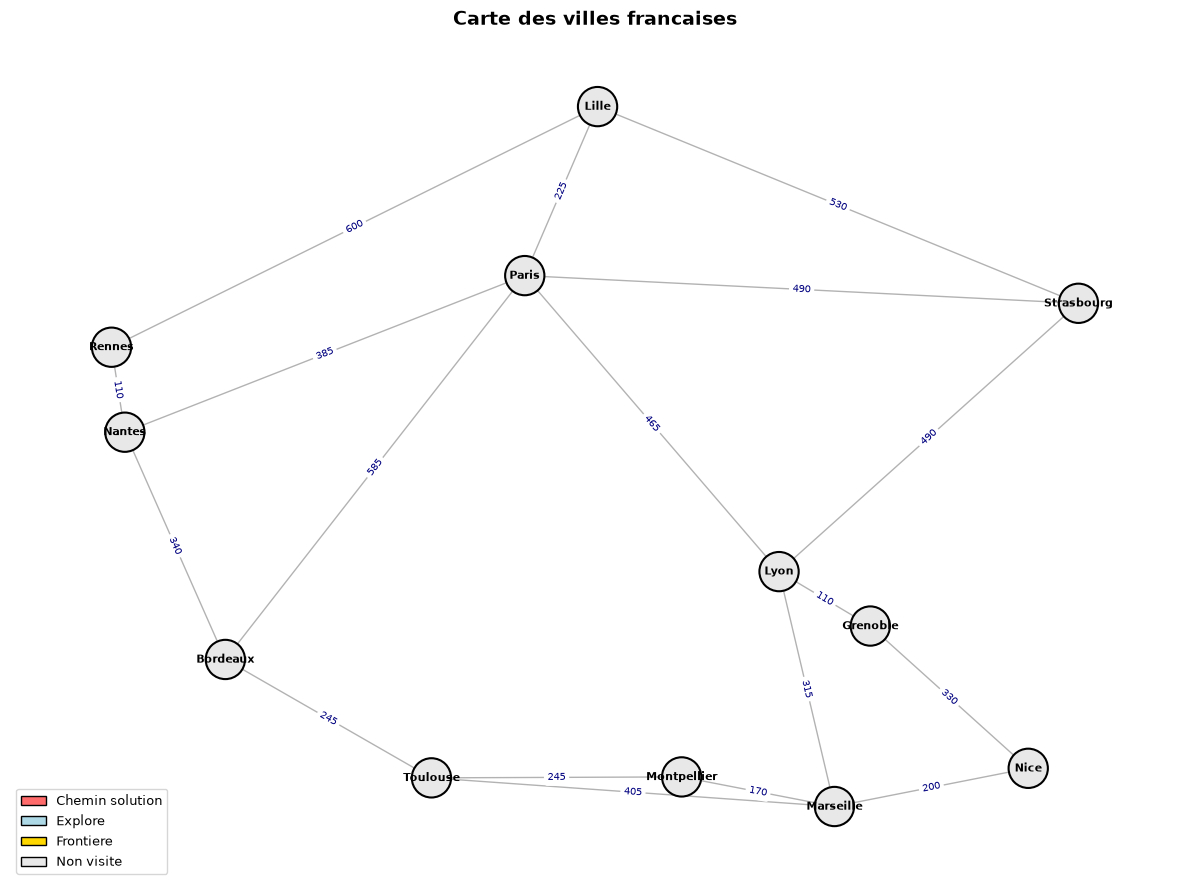

In [5]:
# --- Visualisation du graphe des villes ---

def draw_france_graph(graph, coords, path=None, explored=None,
                      frontier=None, title="Carte des villes"):
    """Dessine le graphe des villes avec un chemin optionnel."""
    G = nx.Graph()
    for city, neighbors in graph.items():
        for neighbor, dist in neighbors.items():
            G.add_edge(city, neighbor, weight=dist)

    fig, ax = plt.subplots(1, 1, figsize=(12, 9))

    # Positions basees sur les coordonnees
    pos = {city: (lon, lat) for city, (lon, lat) in coords.items()}

    # Couleurs des noeuds
    node_colors = []
    for node in G.nodes():
        if path and node in path:
            node_colors.append('#FF6B6B')  # Rouge pour le chemin
        elif explored and node in explored:
            node_colors.append('#ADD8E6')  # Bleu clair pour explores
        elif frontier and node in frontier:
            node_colors.append('#FFD700')  # Jaune pour la frontiere
        else:
            node_colors.append('#E8E8E8')  # Gris pour non visites

    # Dessiner le graphe
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                           node_size=800, edgecolors='black', linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight='bold')

    # Aretes normales
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='gray',
                           width=1.0, alpha=0.6)

    # Distances sur les aretes
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                 ax=ax, font_size=7, font_color='navy')

    # Chemin en surbrillance
    if path and len(path) > 1:
        path_edges = [(path[i], path[i+1]) for i in range(len(path)-1)]
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, ax=ax,
                               edge_color='red', width=3.0, alpha=0.8)

    # Legende
    legend_items = [
        mpatches.Patch(facecolor='#FF6B6B', edgecolor='black', label='Chemin solution'),
        mpatches.Patch(facecolor='#ADD8E6', edgecolor='black', label='Explore'),
        mpatches.Patch(facecolor='#FFD700', edgecolor='black', label='Frontiere'),
        mpatches.Patch(facecolor='#E8E8E8', edgecolor='black', label='Non visite'),
    ]
    ax.legend(handles=legend_items, loc='lower left', fontsize=9)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Afficher le graphe de base
draw_france_graph(france_graph, france_coords, title="Carte des villes francaises")

### Interpretation - Graphe des villes

Le graphe represente 12 villes francaises reliees par des routes ponderes par la distance en km. Nous utiliserons ce graphe comme fil conducteur pour comparer les différents algorithmes.

**problème de reference** : trouver un chemin de **Bordeaux** a **Strasbourg**.

Ce problème est interessant car :
- Plusieurs chemins existent (via Paris, via Lyon, via Toulouse-Marseille-Lyon, etc.)
- Les couts sont non uniformes (les distances varient beaucoup)
- Selon le trajet, BFS (le moins d etapes) et UCS (le moins cher) peuvent donner des chemins differents -- nous le verrons sur le cas Paris -> Rennes

In [6]:
# --- Fonction utilitaire pour tracer une recherche ---

class SearchResult:
    """Resultat d'une recherche, avec statistiques."""

    def __init__(self, algorithm, solution_node=None, nodes_expanded=0,
                 nodes_generated=0, max_frontier_size=0, elapsed_ms=0,
                 explored_order=None):
        self.algorithm = algorithm
        self.solution_node = solution_node
        self.nodes_expanded = nodes_expanded
        self.nodes_generated = nodes_generated
        self.max_frontier_size = max_frontier_size
        self.elapsed_ms = elapsed_ms
        self.explored_order = explored_order or []

    @property
    def found(self):
        return self.solution_node is not None

    @property
    def path(self):
        if self.solution_node:
            return [n.state for n in self.solution_node.path()]
        return []

    @property
    def cost(self):
        if self.solution_node:
            return self.solution_node.path_cost
        return float('inf')

    def display(self):
        print(f"\n--- {self.algorithm} ---")
        if self.found:
            print(f"  Chemin     : {' -> '.join(self.path)}")
            print(f"  Cout total : {self.cost}")
            print(f"  Longueur   : {len(self.path) - 1} étapes")
        else:
            print(f"  Aucune solution trouvee.")
        print(f"  Noeuds explorés  : {self.nodes_expanded}")
        print(f"  Noeuds generes   : {self.nodes_generated}")
        print(f"  Frontiere max    : {self.max_frontier_size}")
        print(f"  Temps            : {self.elapsed_ms:.2f} ms")

print("Framework de recherche pret.")

Framework de recherche pret.


## 3. Recherche en Largeur (BFS - Breadth-First Search)

BFS explore l'arbre de recherche **niveau par niveau** : tous les noeuds de profondeur $d$ sont explores avant ceux de profondeur $d+1$.

### Principe

La frontiere est geree comme une **file FIFO** (First In, First Out) :
- Les noeuds sont ajoutes a la **fin** de la file
- Le noeud a explorer est retire du **debut** de la file

### Proprietes théoriques

| Propriete | Valeur | Condition |
|-----------|--------|----------|
| Completude | Oui | Si $b$ est fini |
| Optimalite | Oui | Si les couts sont uniformes (cout = 1) |
| Complexite temporelle | $O(b^d)$ | |
| Complexite spatiale | $O(b^d)$ | Tous les noeuds de la frontiere en memoire |

In [7]:
def breadth_first_search(problem, verbose=False):
    """
    Recherche en largeur (Graph-Search).
    Frontiere = file FIFO (collections.deque).
    """
    start_time = time.perf_counter()

    node = Node(problem.initial)
    if problem.goal_test(node.state):
        elapsed = (time.perf_counter() - start_time) * 1000
        return SearchResult('BFS', node, 0, 0, 1, elapsed)

    frontier = deque([node])             # File FIFO
    frontier_states = {node.state}       # Pour recherche rapide O(1)
    explored = set()                     # Etats deja explores
    explored_order = []                  # Ordre d'exploration
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        node = frontier.popleft()        # Retirer du debut (FIFO)
        frontier_states.discard(node.state)
        explored.add(node.state)
        explored_order.append(node.state)
        nodes_expanded += 1

        if verbose:
            frontier_preview = [n.state for n in list(frontier)[:5]]
            more = f"... (+{len(frontier)-5})" if len(frontier) > 5 else ""
            print(f"  Explore: {node.state:15s} | Frontiere: {frontier_preview}{more}")

        for child in node.expand(problem):
            nodes_generated += 1
            if child.state not in explored and child.state not in frontier_states:
                if problem.goal_test(child.state):
                    elapsed = (time.perf_counter() - start_time) * 1000
                    explored_order.append(child.state)
                    return SearchResult('BFS', child, nodes_expanded,
                                        nodes_generated, max_frontier,
                                        elapsed, explored_order)
                frontier.append(child)   # Ajouter a la fin (FIFO)
                frontier_states.add(child.state)
                max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('BFS', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order)
print("Fonction breadth_first_search definie (BFS)")

Fonction breadth_first_search definie (BFS)


Testons BFS sur notre problème de reference : trouver un chemin de Bordeaux a Strasbourg.

In [8]:
# --- Application de BFS au problème Bordeaux -> Strasbourg ---

problem_bs = GraphProblem('Bordeaux', 'Strasbourg', france_graph)

print("BFS : Bordeaux -> Strasbourg")
print("=" * 60)
result_bfs = breadth_first_search(problem_bs, verbose=True)
result_bfs.display()

BFS : Bordeaux -> Strasbourg
  Explore: Bordeaux        | Frontiere: []
  Explore: Paris           | Frontiere: ['Toulouse', 'Nantes']

--- BFS ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 étapes
  Noeuds explorés  : 2
  Noeuds generes   : 6
  Frontiere max    : 4
  Temps            : 0.08 ms


### Interpretation - BFS sur les villes francaises

**Sortie obtenue** : BFS explore les villes par "cercles concentriques" autour de Bordeaux.

| étape | Observation |
|-------|-------------|
| Profondeur 0 | Bordeaux (depart) |
| Profondeur 1 | Voisins directs de Bordeaux (Paris, Toulouse, Nantes) |
| Profondeur 2 | Voisins des voisins (Lyon, Lille, Strasbourg via Paris, etc.) |

**Points cles** :
1. BFS trouve le chemin avec le **minimum d'étapes** (le moins de villes intermediaires)
2. Ce n'est **pas** forcement le chemin le plus court en km, car les distances sont non uniformes
3. Le chemin via Paris est direct en nombre d'étapes, mais peut ne pas etre optimal en distance

> **Rappel** : BFS est optimal uniquement quand tous les couts d'action sont identiques.

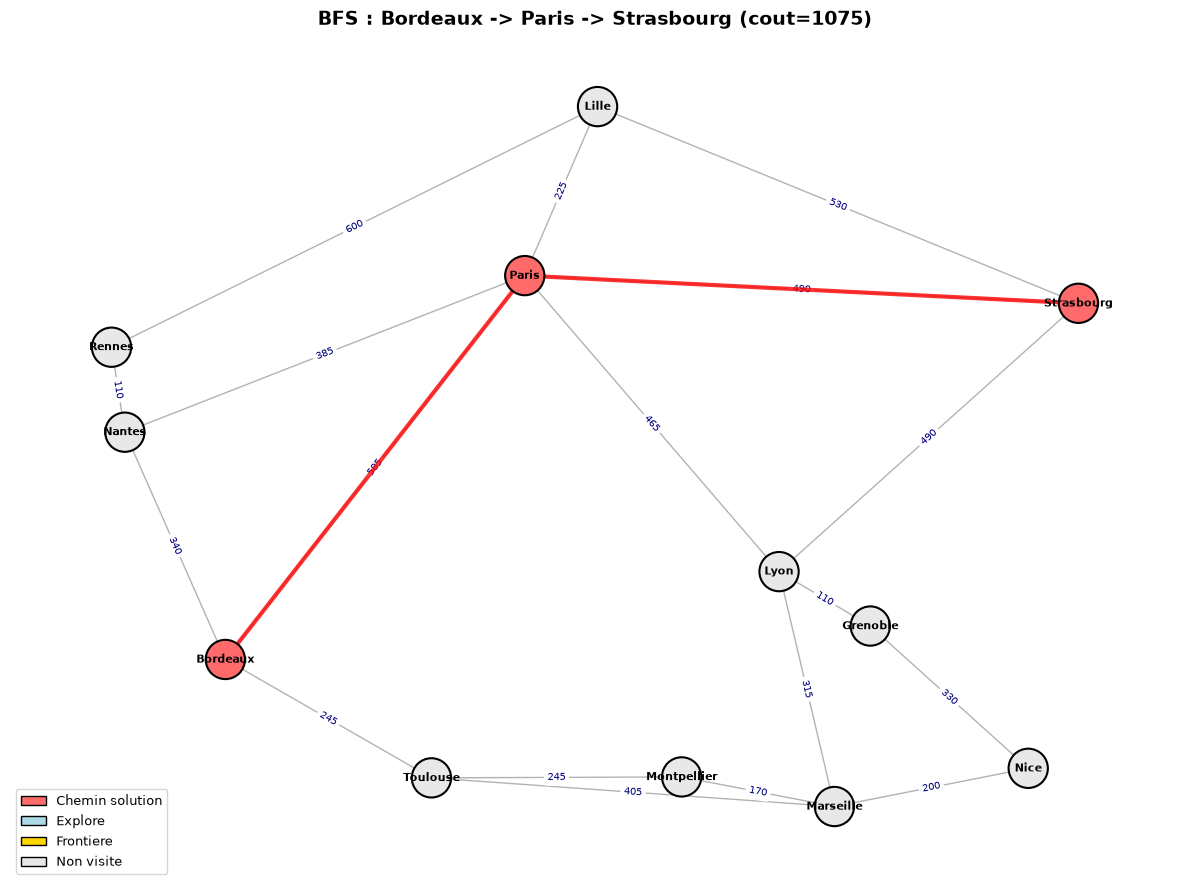

In [9]:
# Visualisation du résultat BFS
draw_france_graph(france_graph, france_coords,
                  path=result_bfs.path,
                  explored=set(result_bfs.explored_order),
                  title=f"BFS : {' -> '.join(result_bfs.path)} (cout={result_bfs.cost})")

## 4. Recherche en Profondeur (DFS - Depth-First Search)

DFS explore l'arbre de recherche en allant **le plus profondement possible** avant de revenir en arriere (backtracking).

### Principe

La frontiere est geree comme une **pile LIFO** (Last In, First Out) :
- Les noeuds sont ajoutes au **sommet** de la pile
- Le noeud a explorer est retire du **sommet** de la pile

### Proprietes théoriques

| Propriete | Valeur | Condition |
|-----------|--------|----------|
| Completude | Non | Peut boucler dans les espaces infinis (Tree-Search) |
| Completude | Oui | Graph-Search dans les espaces finis |
| Optimalite | Non | Peut trouver une solution sous-optimale |
| Complexite temporelle | $O(b^m)$ | $m$ = profondeur maximale |
| Complexite spatiale | $O(bm)$ | Seulement le chemin courant + freres |

In [10]:
def depth_first_search(problem, verbose=False):
    """
    Recherche en profondeur (Graph-Search).
    Frontiere = pile LIFO (liste Python).
    """
    start_time = time.perf_counter()

    node = Node(problem.initial)
    if problem.goal_test(node.state):
        elapsed = (time.perf_counter() - start_time) * 1000
        return SearchResult('DFS', node, 0, 0, 1, elapsed)

    frontier = [node]                    # Pile LIFO
    explored = set()                     # Etats deja explores
    explored_order = []                  # Ordre d'exploration
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        node = frontier.pop()            # Retirer du sommet (LIFO)

        if problem.goal_test(node.state):
            elapsed = (time.perf_counter() - start_time) * 1000
            explored_order.append(node.state)
            return SearchResult('DFS', node, nodes_expanded,
                                nodes_generated, max_frontier,
                                elapsed, explored_order)

        if node.state in explored:
            continue

        explored.add(node.state)
        explored_order.append(node.state)
        nodes_expanded += 1

        if verbose:
            frontier_preview = [n.state for n in frontier[-5:]]
            print(f"  Explore: {node.state:15s} (prof={node.depth}) | "
                  f"Pile: {frontier_preview}")

        for child in node.expand(problem):
            nodes_generated += 1
            if child.state not in explored:
                frontier.append(child)   # Empiler (LIFO)
                max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('DFS', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order)
print("Fonction depth_first_search definie (DFS)")

Fonction depth_first_search definie (DFS)


Appliquons DFS au même problème Bordeaux-Strasbourg pour comparer avec BFS.

In [11]:
# --- Application de DFS au problème Bordeaux -> Strasbourg ---

print("DFS : Bordeaux -> Strasbourg")
print("=" * 60)
result_dfs = depth_first_search(problem_bs, verbose=True)
result_dfs.display()

DFS : Bordeaux -> Strasbourg
  Explore: Bordeaux        (prof=0) | Pile: []
  Explore: Nantes          (prof=1) | Pile: ['Paris', 'Toulouse']
  Explore: Rennes          (prof=2) | Pile: ['Paris', 'Toulouse', 'Paris']
  Explore: Lille           (prof=3) | Pile: ['Paris', 'Toulouse', 'Paris']

--- DFS ---
  Chemin     : Bordeaux -> Nantes -> Rennes -> Lille -> Strasbourg
  Cout total : 1580
  Longueur   : 4 étapes
  Noeuds explorés  : 4
  Noeuds generes   : 11
  Frontiere max    : 5
  Temps            : 0.11 ms


### Interpretation - DFS vs BFS

**Sortie obtenue** : DFS suit un chemin en profondeur avant de considerer les alternatives.

| Aspect | BFS | DFS |
|--------|-----|-----|
| stratégie | Explore par niveaux | Explore une branche a fond |
| Chemin trouve | Minimum d'étapes | Pas forcement le plus court |
| Memoire | Stocke tout le niveau courant | Stocke seulement la branche courante |

**Observations** :
1. DFS peut trouver un chemin **plus long** que BFS (en nombre d'étapes)
2. L'**ordre d'exploration** est très différent : DFS "fonce" dans une direction
3. La **frontiere maximale** de DFS est généralement plus petite que celle de BFS

> **Avantage de DFS** : memoire lineaire en $O(bm)$ contre $O(b^d)$ pour BFS. Pour un arbre de profondeur 20 et de branchement 10, DFS utilise ~200 noeuds vs ~$10^{20}$ pour BFS.

### Exercice 1 : DFS avec limite de profondeur

**Objectif** : Implementez `dfs_limited`, une variante de DFS qui s'arrete après une profondeur maximale donnee. Cette variante est la brique de base de l'algorithme IDDFS.

**Consignes** :
1. Implementez `dfs_limited(problem, max_depth)` qui explore en profondeur mais s'arrete a `max_depth`
2. Testez sur le trajet Bordeaux -> Strasbourg avec différentes limites (1, 2, 3, 4)
3. Observez a partir de quelle profondeur la solution est trouvee

**Indices** :
- Inspirez-vous de `depth_first_search` mais ajoutez un test `node.depth >= max_depth`
- Utilisez `GraphProblem('Bordeaux', 'Strasbourg', france_graph)`
- La solution est a profondeur 2 (Bordeaux -> Paris -> Strasbourg)

In [12]:
# --- Exercice 1 : DFS avec limite de profondeur ---

def dfs_limited(problem, max_depth, verbose=False):
    """
    Recherche en profondeur avec limite de profondeur.
    
    TODO etudiant : implementez cette fonction
    
    Args:
        problem: Probleme de recherche (GraphProblem)
        max_depth: Profondeur maximale d'exploration
        verbose: Afficher les etapes
    
    Returns:
        SearchResult ou None si pas de solution a cette profondeur
    
    Indices :
        - Inspirez-vous de depth_first_search ci-dessus
        - Ajoutez un test : si node.depth >= max_depth, ne pas expanser ce noeud
        - Retournez None si la solution n'est pas trouvee a cette profondeur
    """
    # TODO étudiant : implementer le DFS avec limite
    # Etape 1 : initialiser noeud, frontiere (pile LIFO), explored (set)
    # Etape 2 : boucle principale (retirer sommet de la pile)
    # Etape 3 : si goal_test -> retourner SearchResult
    # Etape 4 : si node.depth < max_depth -> expanser et empiler les enfants
    # Etape 5 : si frontiere vide -> retourner None
    return None  # TODO etudiant : remplacer

# Test avec différentes profondeurs
# problem_test = GraphProblem('Bordeaux', 'Strasbourg', france_graph)
# for depth in [1, 2, 3, 4]:
#     result = dfs_limited(problem_test, max_depth=depth)
#     if result and result.found:
#         print(f"Profondeur {depth}: TROUVE - {result.path} (cout={result.cost})")
#     else:
#         print(f"Profondeur {depth}: pas de solution")

print("Exercice a completer")

Exercice a completer


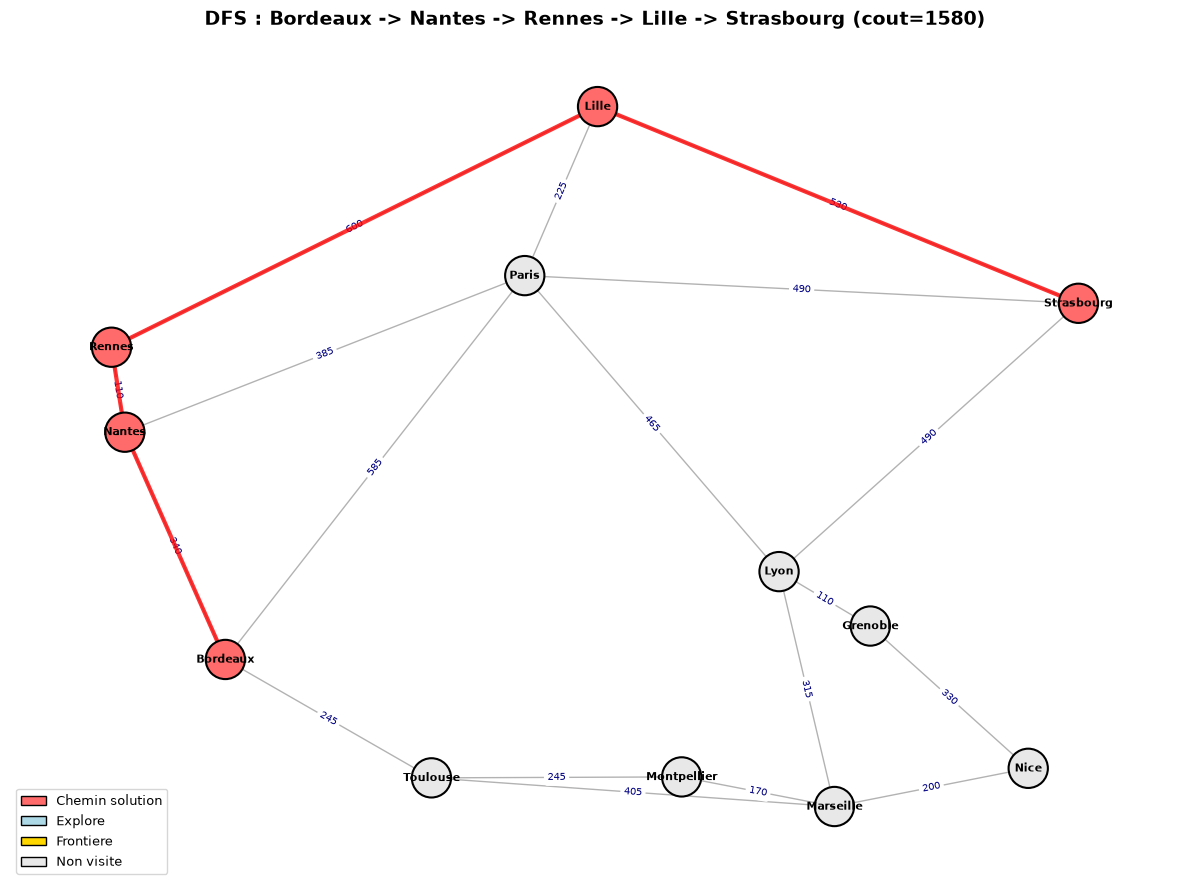

In [13]:
# Visualisation du résultat DFS
draw_france_graph(france_graph, france_coords,
                  path=result_dfs.path,
                  explored=set(result_dfs.explored_order),
                  title=f"DFS : {' -> '.join(result_dfs.path)} (cout={result_dfs.cost})")

### Illustration : Ordre d'expansion BFS vs DFS sur un arbre

Pour mieux comprendre la différence, visualisons l'ordre d'expansion sur un petit arbre binaire.

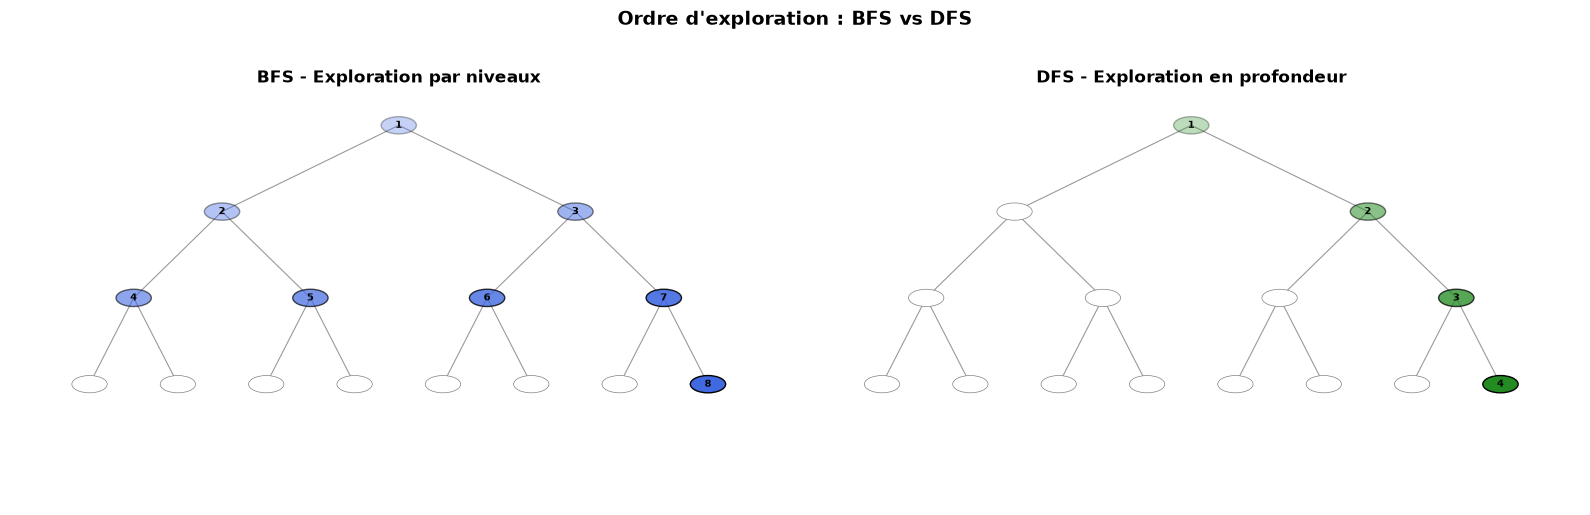

BFS : 8 noeuds explorés, chemin de longueur 3
DFS : 4 noeuds explorés, chemin de longueur 3


In [14]:
# --- Comparaison visuelle BFS vs DFS sur un arbre binaire ---

def build_binary_tree_graph(depth=3):
    """Construit un graphe representant un arbre binaire."""
    graph = {}
    goal_node = None
    for d in range(depth):
        for i in range(2**d):
            node = f"N{d}_{i}"
            graph[node] = {}
            # Fils gauche et droit
            if d < depth - 1:
                left = f"N{d+1}_{2*i}"
                right = f"N{d+1}_{2*i+1}"
                graph[node][left] = 1
                graph[node][right] = 1
            else:
                # Le but est la dernière feuille
                goal_node = node
    return graph, goal_node

tree_graph, tree_goal = build_binary_tree_graph(depth=4)
tree_problem = GraphProblem('N0_0', tree_goal, tree_graph)

# Executer BFS et DFS
bfs_tree = breadth_first_search(tree_problem)
dfs_tree = depth_first_search(tree_problem)

# Afficher les ordres d'exploration
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, result, color, title in [
    (axes[0], bfs_tree, '#4169E1', 'BFS - Exploration par niveaux'),
    (axes[1], dfs_tree, '#228B22', 'DFS - Exploration en profondeur'),
]:
    order = result.explored_order
    # Creer les positions pour l'arbre
    positions = {}
    for name in tree_graph:
        parts = name.split('_')
        d = int(parts[0][1:])
        i = int(parts[1])
        x = (i + 0.5) / (2**d)
        y = 1.0 - d * 0.25
        positions[name] = (x, y)

    # Dessiner les aretes
    for node_name, neighbors in tree_graph.items():
        for neighbor in neighbors:
            if node_name in positions and neighbor in positions:
                x1, y1 = positions[node_name]
                x2, y2 = positions[neighbor]
                ax.plot([x1, x2], [y1, y2], 'k-', linewidth=0.8, alpha=0.4)

    # Dessiner les noeuds avec le numéro d'exploration
    for idx, node_name in enumerate(order):
        if node_name in positions:
            x, y = positions[node_name]
            circle = plt.Circle((x, y), 0.025, color=color,
                                ec='black', linewidth=1, zorder=5,
                                alpha=0.3 + 0.7 * (idx / max(len(order)-1, 1)))
            ax.add_patch(circle)
            ax.text(x, y, str(idx+1), ha='center', va='center',
                    fontsize=7, fontweight='bold', zorder=6)

    # Noeuds non explorés
    for node_name in tree_graph:
        if node_name not in order and node_name in positions:
            x, y = positions[node_name]
            circle = plt.Circle((x, y), 0.025, color='white',
                                ec='gray', linewidth=0.5, zorder=5)
            ax.add_patch(circle)

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.1, 1.1)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle("Ordre d'exploration : BFS vs DFS", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"BFS : {len(bfs_tree.explored_order)} noeuds explorés, "
      f"chemin de longueur {len(bfs_tree.path)-1}")
print(f"DFS : {len(dfs_tree.explored_order)} noeuds explorés, "
      f"chemin de longueur {len(dfs_tree.path)-1}")

### Interpretation - Ordres d'exploration

Les numéros dans les noeuds indiquent l'**ordre d'exploration** :

| Algorithme | Ordre | Comportement |
|------------|-------|-------------|
| BFS | 1, 2, 3, 4, 5, 6, 7, ... | Balaye chaque niveau completement avant le suivant |
| DFS | 1, 2, 4, 8, ... puis backtrack | Descend au plus profond, puis remonte |

**Points cles** :
1. BFS garantit de trouver le noeud but **le plus proche** (profondeur minimale)
2. DFS peut trouver le but **plus vite** s'il est du "bon cote" de l'arbre
3. DFS peut aussi explorer **beaucoup plus** de noeuds si le but est du "mauvais cote"

## 5. Recherche a Cout Uniforme (UCS - Uniform Cost Search)

UCS generalise BFS aux graphes avec des **couts non uniformes**. Au lieu d'explorer par profondeur, il explore par **cout croissant**.

### Principe

La frontiere est geree comme une **file de priorite** (min-heap) ordonnee par le cout du chemin $g(n)$ :
- Le noeud de **cout minimal** est explore en premier
- Equivalent a l'algorithme de Dijkstra pour un objectif unique

### Proprietes théoriques

| Propriete | Valeur | Condition |
|-----------|--------|----------|
| Completude | Oui | Si $\epsilon > 0$ (couts strictement positifs) |
| Optimalite | Oui | Toujours (tant que $\epsilon > 0$) |
| Complexite temporelle | $O(b^{1+\lfloor C^*/\epsilon \rfloor})$ | |
| Complexite spatiale | $O(b^{1+\lfloor C^*/\epsilon \rfloor})$ | |

In [15]:
def uniform_cost_search(problem, verbose=False):
    """
    Recherche a cout uniforme (Graph-Search).
    Frontiere = file de priorite (heapq), ordonnee par path_cost.
    """
    start_time = time.perf_counter()

    node = Node(problem.initial)
    frontier = []                        # Min-heap
    counter = 0                          # Tie-breaker pour heapq
    heapq.heappush(frontier, (node.path_cost, counter, node))
    counter += 1
    frontier_map = {node.state: node.path_cost}  # etat -> meilleur cout connu
    explored = set()
    explored_order = []
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        cost, _, node = heapq.heappop(frontier)

        if problem.goal_test(node.state):
            elapsed = (time.perf_counter() - start_time) * 1000
            explored_order.append(node.state)
            return SearchResult('UCS', node, nodes_expanded,
                                nodes_generated, max_frontier,
                                elapsed, explored_order)

        if node.state in explored:
            continue

        explored.add(node.state)
        explored_order.append(node.state)
        nodes_expanded += 1

        if verbose:
            print(f"  Explore: {node.state:15s} (cout={node.path_cost:6.0f}) | "
                  f"Frontiere: {len(frontier)} noeuds")

        for child in node.expand(problem):
            nodes_generated += 1
            if child.state not in explored:
                old_cost = frontier_map.get(child.state, float('inf'))
                if child.path_cost < old_cost:
                    heapq.heappush(frontier, (child.path_cost, counter, child))
                    counter += 1
                    frontier_map[child.state] = child.path_cost
                    max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('UCS', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order)
print("Fonction uniform_cost_search definie (UCS)")

Fonction uniform_cost_search definie (UCS)


Appliquons UCS a notre problème de reference et comparons avec les résultats de BFS.

In [16]:
# --- Application de UCS au problème Bordeaux -> Strasbourg ---

print("UCS : Bordeaux -> Strasbourg")
print("=" * 60)
result_ucs = uniform_cost_search(problem_bs, verbose=True)
result_ucs.display()
print("\nNOTE : sur Bordeaux -> Strasbourg, BFS et UCS trouvent le MEME chemin.")
print("C'est un cas ou couts et nombre d'étapes coincident : l'avantage de UCS sur les couts n'est pas visible.")
print("Voir le trajet Paris -> Rennes ci-dessous, ou UCS trouve un chemin ~1,7x moins cher.")


UCS : Bordeaux -> Strasbourg
  Explore: Bordeaux        (cout=     0) | Frontiere: 0 noeuds
  Explore: Toulouse        (cout=   245) | Frontiere: 2 noeuds
  Explore: Nantes          (cout=   340) | Frontiere: 3 noeuds
  Explore: Rennes          (cout=   450) | Frontiere: 3 noeuds
  Explore: Montpellier     (cout=   490) | Frontiere: 3 noeuds
  Explore: Paris           (cout=   585) | Frontiere: 2 noeuds
  Explore: Marseille       (cout=   650) | Frontiere: 4 noeuds
  Explore: Lille           (cout=   810) | Frontiere: 5 noeuds
  Explore: Nice            (cout=   850) | Frontiere: 4 noeuds
  Explore: Lyon            (cout=   965) | Frontiere: 4 noeuds

--- UCS ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 étapes
  Noeuds explorés  : 10
  Noeuds generes   : 31
  Frontiere max    : 6
  Temps            : 0.23 ms

NOTE : sur Bordeaux -> Strasbourg, BFS et UCS trouvent le MEME chemin.
C'est un cas ou couts et nombre d'étapes coincident : l'avantage 

### Quand l'avantage de cout de UCS devient visible : Paris -> Rennes

Sur le trajet Bordeaux -> Strasbourg, BFS et UCS ont trouve le même chemin
(1075 km en 2 étapes). Le résultat est correct — il est même instructif —
mais il ne montre **pas** l'avantage propre de UCS : sur ce graphe, l'arc
le moins cher entre deux villes est généralement aussi le plus court en
nombre d'étapes, donc BFS (profondeur minimale) et UCS (cout minimal)
convergent.

Prenons **Paris -> Rennes**. Depuis Paris, deux chemins en 2 étapes existent :

| Chemin | étapes | Cout (km) |
|--------|--------|----------|
| Paris -> Lille -> Rennes | 2 | 225 + 600 = **825** |
| Paris -> Nantes -> Rennes | 2 | 385 + 110 = **495** |

même longueur, couts divises par ~1,7. BFS, qui ne raisonne qu'en nombre
de sauts, traite les deux chemins comme equivalents et developpe le premier
qu'il rencontre dans l'ordre du graphe (Lille avant Nantes). UCS, lui, suit
le front `g(n)` : 495 < 825, donc il developpe la frontiere Nantes avant
Lille et trouve le chemin 40% moins cher. **C'est ici que l'optimalite en
cout de UCS devient visible dans la sortie.**


In [17]:
# --- Cas discriminant : Paris -> Rennes (UCS divise le cout par deux) ---

import pandas as pd

problem_pr = GraphProblem('Paris', 'Rennes', france_graph)

print("Comparaison : BFS vs UCS sur Paris -> Rennes")
print("=" * 70)

result_bfs_pr = breadth_first_search(problem_pr, verbose=True)
result_ucs_pr = uniform_cost_search(problem_pr, verbose=True)

comparison_pr_df = pd.DataFrame([
    {
        'Algorithme': 'BFS',
        'Chemin': ' -> '.join(result_bfs_pr.path),
        'Cout (km)': result_bfs_pr.cost,
        'Longueur': len(result_bfs_pr.path) - 1,
        'Noeuds explorés': result_bfs_pr.nodes_expanded,
        'Temps (ms)': f"{result_bfs_pr.elapsed_ms:.2f}",
    },
    {
        'Algorithme': 'UCS',
        'Chemin': ' -> '.join(result_ucs_pr.path),
        'Cout (km)': result_ucs_pr.cost,
        'Longueur': len(result_ucs_pr.path) - 1,
        'Noeuds explorés': result_ucs_pr.nodes_expanded,
        'Temps (ms)': f"{result_ucs_pr.elapsed_ms:.2f}",
    },
])

print(comparison_pr_df.to_string(index=False))

print("\n" + "=" * 70)
if result_bfs_pr.cost > result_ucs_pr.cost:
    diff = result_bfs_pr.cost - result_ucs_pr.cost
    pct = (diff / result_bfs_pr.cost) * 100
    print(f"UCS a trouve un chemin {diff:.0f} km plus court ({pct:.1f}% de moins).")
    print("BFS a developpe Lille en premier (premier voisin alphabetique) et s'est")
    print("arrete la : 225 + 600 = 825 km. UCS, en suivant le cout cumule g(n), a")
    print("developpe Nantes en premier et trouve 385 + 110 = 495 km. Meme nombre")
    print("d'étapes, mais UCS est garanti optimal en cout.")
elif result_bfs_pr.cost == result_ucs_pr.cost:
    print("NOTE : BFS egale UCS sur ce trajet (tie).")
else:
    print("NOTE : BFS strictement meilleur (ne devrait pas arriver).")


Comparaison : BFS vs UCS sur Paris -> Rennes
  Explore: Paris           | Frontiere: []
  Explore: Lyon            | Frontiere: ['Lille', 'Strasbourg', 'Nantes', 'Bordeaux']
  Explore: Lille           | Frontiere: ['Strasbourg', 'Nantes', 'Bordeaux', 'Marseille', 'Grenoble']
  Explore: Paris           (cout=     0) | Frontiere: 0 noeuds
  Explore: Lille           (cout=   225) | Frontiere: 4 noeuds
  Explore: Nantes          (cout=   385) | Frontiere: 4 noeuds
  Explore: Lyon            (cout=   465) | Frontiere: 4 noeuds
  Explore: Strasbourg      (cout=   490) | Frontiere: 5 noeuds
Algorithme                    Chemin  Cout (km)  Longueur  Noeuds explorés Temps (ms)
       BFS  Paris -> Lille -> Rennes        825         2                3       0.10
       UCS Paris -> Nantes -> Rennes        495         2                5       0.14

UCS a trouve un chemin 330 km plus court (40.0% de moins).
BFS a developpe Lille en premier (premier voisin alphabetique) et s'est
arrete la : 225 + 6

### Interpretation - UCS trouve le chemin optimal

**Sortie obtenue** : UCS explore les noeuds par **cout croissant**, garantissant l'optimalite.

| Aspect | BFS | UCS |
|--------|-----|-----|
| Critere d'expansion | Profondeur minimale | Cout minimal |
| Optimalite | Uniquement si couts uniformes | Toujours |
| Frontiere | File FIFO | File de priorite |

**Observations** :
1. UCS peut explorer plus de noeuds que BFS (il suit les routes les moins cheres, pas les plus directes)
2. Le chemin trouve est garanti **optimal en distance** (km)
3. L'ordre d'exploration depend des couts : une ville eloignee en étapes peut etre exploree tot si elle est accessible par une route courte

> **Point important** : Quand les couts sont identiques (tous egaux a 1), UCS se comporte exactement comme BFS.
**Exemple discriminant (Paris -> Rennes)** : BFS trouve `Paris -> Lille -> Rennes` (825 km)
et UCS trouve `Paris -> Nantes -> Rennes` (495 km) — **même nombre d'étapes** mais UCS
ecarte 40% de cout. La capacite de UCS a sélectionner le chemin le moins cher n'est pas
visible sur Bordeaux -> Strasbourg (ou BFS ≡ UCS) ; elle devient visible sur ce trajet ou
plusieurs chemins de même longueur existent avec des couts très différents.


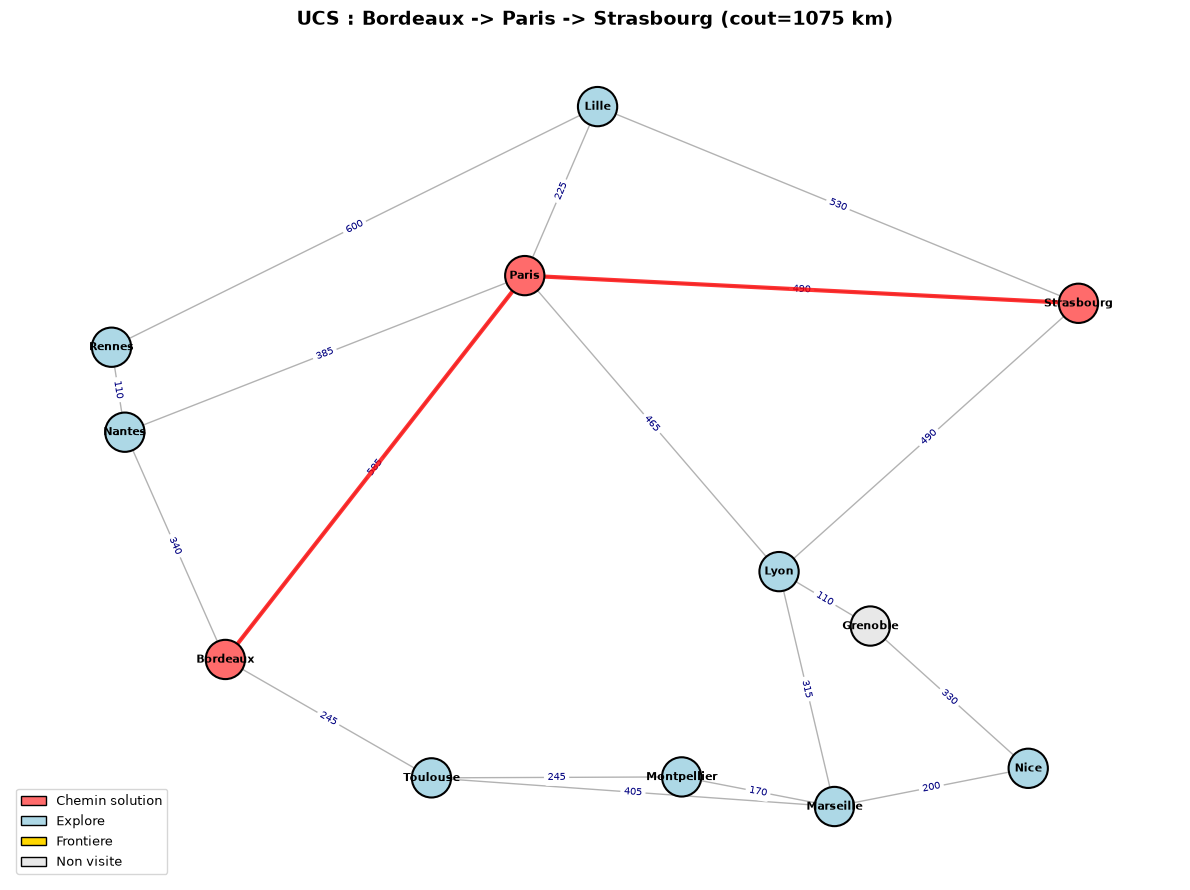

In [18]:
# Visualisation du résultat UCS
draw_france_graph(france_graph, france_coords,
                  path=result_ucs.path,
                  explored=set(result_ucs.explored_order),
                  title=f"UCS : {' -> '.join(result_ucs.path)} (cout={result_ucs.cost} km)")

### Exemple guidé — Analyser l'écart de coût entre BFS et UCS

*Exercice 2 résolu dans la PR #22647 et repris ici comme exemple guidé.*

**Question d'origine** : identifier un trajet de `france_graph` où BFS et UCS trouvent des chemins de coûts différents, puis expliquer pourquoi.

**Ce que montre la solution** :
- elle ne se contente pas du trajet suggéré : une **étape 0** cherche automatiquement, parmi tous les couples (départ, arrivée), ceux où les deux algorithmes divergent ;
- sur Rennes → Nice, elle affiche les deux chemins **arête par arête** et calcule leur coût avec `cout_chemin`, au lieu de le recopier ;
- trois `assert` vérifient que les coûts annoncés par les algorithmes sont bien la somme des arêtes, et que UCS ne fait jamais pire que BFS ;
- un **cas limite** (Bordeaux → Strasbourg) montre un trajet sans écart ;
- l'explication finale identifie les tronçons qui diffèrent et les arêtes courtes que UCS exploite.

L'exercice 5, en fin de carnet, prolonge cette analyse : il change la **fonction de coût** elle-même.

In [19]:
# --- Exemple guide : analyser l'ecart de cout entre BFS et UCS ---
# (exercice 2 resolu dans la PR #22647)

def cout_chemin(graph, chemin):
    """Cout d'un chemin = somme des distances de ses aretes (calcule, pas code en dur)."""
    return sum(graph[a][b] for a, b in zip(chemin, chemin[1:]))

def comparer(depart, arrivee, graph=france_graph):
    """Execute BFS et UCS sur depart -> arrivee et renvoie (probleme, res_bfs, res_ucs)."""
    probleme = GraphProblem(depart, arrivee, graph)
    return probleme, breadth_first_search(probleme), uniform_cost_search(probleme)

# Etape 0 : chercher automatiquement les trajets ou BFS et UCS divergent
divergents = []
for d in france_graph:
    for a in france_graph:
        if d != a:
            _, rb, ru = comparer(d, a)
            if rb.cost != ru.cost:
                divergents.append((d, a, rb.cost, ru.cost))
print(f"{len(divergents)} trajets (sur {len(france_graph) * (len(france_graph) - 1)}) "
      f"ou BFS et UCS trouvent des couts differents.")

# Choix du trajet propose par l'indice : meme nombre d'etapes, cout different
depart_6 = 'Rennes'
arrivee_6 = 'Nice'

problem_6 = GraphProblem(depart_6, arrivee_6, france_graph)
res_bfs_6 = breadth_first_search(problem_6)
res_ucs_6 = uniform_cost_search(problem_6)

print(f"\n=== {depart_6} -> {arrivee_6} ===")
res_bfs_6.display()
res_ucs_6.display()

# Detail arete par arete des deux chemins
for res in (res_bfs_6, res_ucs_6):
    print(f"\n{res.algorithm} : detail des aretes")
    for a, b in zip(res.path, res.path[1:]):
        print(f"  {a:10s} -> {b:10s} {france_graph[a][b]:4d} km")
    print(f"  {'Total':<26s} {cout_chemin(france_graph, res.path):4d} km")

# Verifications : les couts annonces par les algorithmes sont bien ceux des aretes
assert res_bfs_6.cost == cout_chemin(france_graph, res_bfs_6.path)
assert res_ucs_6.cost == cout_chemin(france_graph, res_ucs_6.path)
assert res_ucs_6.cost <= res_bfs_6.cost          # UCS est optimal en cout

ecart = res_bfs_6.cost - res_ucs_6.cost
print(f"\nEcart : {res_bfs_6.cost} - {res_ucs_6.cost} = {ecart} km "
      f"({100 * ecart / res_bfs_6.cost:.1f}% de moins avec UCS), "
      f"pour {len(res_bfs_6.path) - 1} vs {len(res_ucs_6.path) - 1} etapes.")

# Cas limite : trajet ou BFS et UCS trouvent le meme chemin (pas d'ecart)
_, rb0, ru0 = comparer('Bordeaux', 'Strasbourg')
print(f"\nCas limite Bordeaux -> Strasbourg : BFS = {rb0.cost} km, UCS = {ru0.cost} km "
      f"-> {'meme cout' if rb0.cost == ru0.cost else 'couts differents'}.")

print("""
Explication :
- BFS minimise le NOMBRE d'etapes et ignore les distances. Ici les deux chemins ont 5 etapes :
  pour BFS ils se valent, il garde simplement le premier trouve (ordre des voisins dans le graphe).
  Il passe donc par Paris et Lyon. Les deux chemins partagent Rennes -> Nantes (110) et
  Marseille -> Nice (200) ; seul le troncon central differe :
  Nantes -> Paris -> Lyon -> Marseille = 385 + 465 + 315 = 1165 km, soit 110 + 1165 + 200 = 1475 km au total.
- UCS developpe toujours le noeud de plus petit cout cumule g(n). Il prefere la route du sud-ouest
  Nantes -> Bordeaux -> Toulouse -> Marseille = 340 + 245 + 405 = 990 km,
  soit 110 + 990 + 200 = 1300 km au total : 175 km de moins.
- Les aretes exploitees par UCS (Nantes-Bordeaux 340, Bordeaux-Toulouse 245) sont courtes comparees
  a Nantes-Paris 385 et Paris-Lyon 465 : un detour par le sud-ouest, mais moins cher au total.
- Conclusion : quand les couts ne sont pas uniformes, le nombre d'etapes ne mesure pas le cout.
  Seul UCS garantit le chemin de cout minimal.
""")

26 trajets (sur 132) ou BFS et UCS trouvent des couts differents.

=== Rennes -> Nice ===

--- BFS ---
  Chemin     : Rennes -> Nantes -> Paris -> Lyon -> Marseille -> Nice
  Cout total : 1475
  Longueur   : 5 étapes
  Noeuds explorés  : 9
  Noeuds generes   : 29
  Frontiere max    : 3
  Temps            : 0.05 ms

--- UCS ---
  Chemin     : Rennes -> Nantes -> Bordeaux -> Toulouse -> Marseille -> Nice
  Cout total : 1300
  Longueur   : 5 étapes
  Noeuds explorés  : 11
  Noeuds generes   : 34
  Frontiere max    : 4
  Temps            : 0.06 ms

BFS : detail des aretes
  Rennes     -> Nantes      110 km
  Nantes     -> Paris       385 km
  Paris      -> Lyon        465 km
  Lyon       -> Marseille   315 km
  Marseille  -> Nice        200 km
  Total                      1475 km

UCS : detail des aretes
  Rennes     -> Nantes      110 km
  Nantes     -> Bordeaux    340 km
  Bordeaux   -> Toulouse    245 km
  Toulouse   -> Marseille   405 km
  Marseille  -> Nice        200 km
  Total      

## 6. Recherche en Profondeur Iteree (IDDFS - Iterative Deepening DFS)

IDDFS combine les avantages de BFS (completude, optimalite avec couts uniformes) et de DFS (faible consommation memoire).

### Principe

IDDFS execute une serie de **recherches en profondeur limitee** (Depth-Limited Search) avec des limites croissantes : 0, 1, 2, 3, ...

A chaque itération :
1. DFS avec limite de profondeur $\ell$
2. Si solution trouvee : retourner
3. Sinon : incrementer $\ell$ et recommencer depuis la racine

### Proprietes théoriques

| Propriete | Valeur | Condition |
|-----------|--------|----------|
| Completude | Oui | Si $b$ est fini |
| Optimalite | Oui | Si les couts sont uniformes |
| Complexite temporelle | $O(b^d)$ | même ordre que BFS |
| Complexite spatiale | $O(bd)$ | Lineaire (même que DFS) |

### L'overhead est negligeable

On pourrait penser que re-explorer les niveaux superieurs est couteux. En realite, le nombre total de noeuds generes est :

$$N(IDDFS) = (d)b + (d-1)b^2 + ... + (1)b^d$$

Pour $b=10, d=5$ : $N(IDDFS) = 123\,456$ vs $N(BFS) = 111\,111$. L'overhead n'est que d'environ 11%.

In [20]:
def depth_limited_search(problem, limit, verbose=False):
    """
    Recherche en profondeur limitee.
    Retourne (result_node, cutoff_occurred)
    """
    nodes_expanded = 0
    nodes_generated = 0
    explored_order = []

    def recursive_dls(node, limit_remaining):
        nonlocal nodes_expanded, nodes_generated

        if problem.goal_test(node.state):
            explored_order.append(node.state)
            return node, False  # Trouve, pas de coupure

        if limit_remaining == 0:
            return None, True   # Coupure : limite atteinte

        explored_order.append(node.state)
        nodes_expanded += 1
        cutoff_occurred = False

        for child in node.expand(problem):
            nodes_generated += 1
            result, cutoff = recursive_dls(child, limit_remaining - 1)
            if cutoff:
                cutoff_occurred = True
            elif result is not None:
                return result, False

        return None, cutoff_occurred

    root = Node(problem.initial)
    result, cutoff = recursive_dls(root, limit)
    return result, cutoff, nodes_expanded, nodes_generated, explored_order


def iterative_deepening_search(problem, max_depth=50, verbose=False):
    """
    Recherche en profondeur iteree (IDDFS).
    Enchaine des DFS limitees avec des profondeurs croissantes.
    """
    start_time = time.perf_counter()
    total_expanded = 0
    total_generated = 0
    all_explored = []

    for depth_limit in range(max_depth + 1):
        result, cutoff, expanded, generated, explored = \
            depth_limited_search(problem, depth_limit)

        total_expanded += expanded
        total_generated += generated

        if verbose:
            status = "Solution!" if result else ("Coupure" if cutoff else "Echec")
            print(f"  Limite={depth_limit:2d} | Explores={expanded:4d} | "
                  f"Generes={generated:4d} | {status}")

        if result is not None:
            elapsed = (time.perf_counter() - start_time) * 1000
            # Fusionner les noeuds explorés de la dernière itération
            all_explored = explored
            return SearchResult('IDDFS', result, total_expanded,
                                total_generated, depth_limit,
                                elapsed, all_explored)

        if not cutoff:
            break  # Espace entier explore, pas de solution

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('IDDFS', None, total_expanded, total_generated,
                        0, elapsed, all_explored)
print("Fonction depth_limited_search definie (DLS)")

Fonction depth_limited_search definie (DLS)


Appliquons maintenant IDDFS a notre problème de reference et observons le comportement iteratif.

In [21]:
# --- Application de IDDFS au problème Bordeaux -> Strasbourg ---

print("IDDFS : Bordeaux -> Strasbourg")
print("=" * 60)
result_iddfs = iterative_deepening_search(problem_bs, verbose=True)
result_iddfs.display()

IDDFS : Bordeaux -> Strasbourg
  Limite= 0 | Explores=   0 | Generes=   0 | Coupure
  Limite= 1 | Explores=   1 | Generes=   3 | Coupure
  Limite= 2 | Explores=   2 | Generes=   4 | Solution!

--- IDDFS ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 étapes
  Noeuds explorés  : 3
  Noeuds generes   : 7
  Frontiere max    : 2
  Temps            : 0.11 ms


### Interpretation - IDDFS et l'overhead de re-exploration

**Sortie obtenue** : IDDFS teste successivement les limites de profondeur 0, 1, 2, ... jusqu'a trouver une solution.

| itération | Limite | Noeuds explores | résultat |
|-----------|--------|-----------------|----------|
| 1 | 0 | 0 | Coupure (profondeur insuffisante) |
| 2 | 1 | quelques | Coupure |
| ... | ... | ... | ... |
| dernière | $d$ | tous les niveaux $\leq d$ | Solution trouvee |

**Points cles** :
1. IDDFS trouve le **même chemin** que BFS (même profondeur minimale)
2. L'overhead de re-exploration est **modeste** : les niveaux superieurs contiennent peu de noeuds
3. La memoire utilisee est **lineaire** en $O(bd)$, pas exponentielle comme BFS
4. C'est l'algorithme recommande quand on ne connait pas la profondeur de la solution

> **Recommandation AIMA** : IDDFS est généralement la méthode de recherche non informee preferee quand l'espace de recherche est grand et la profondeur de la solution inconnue.

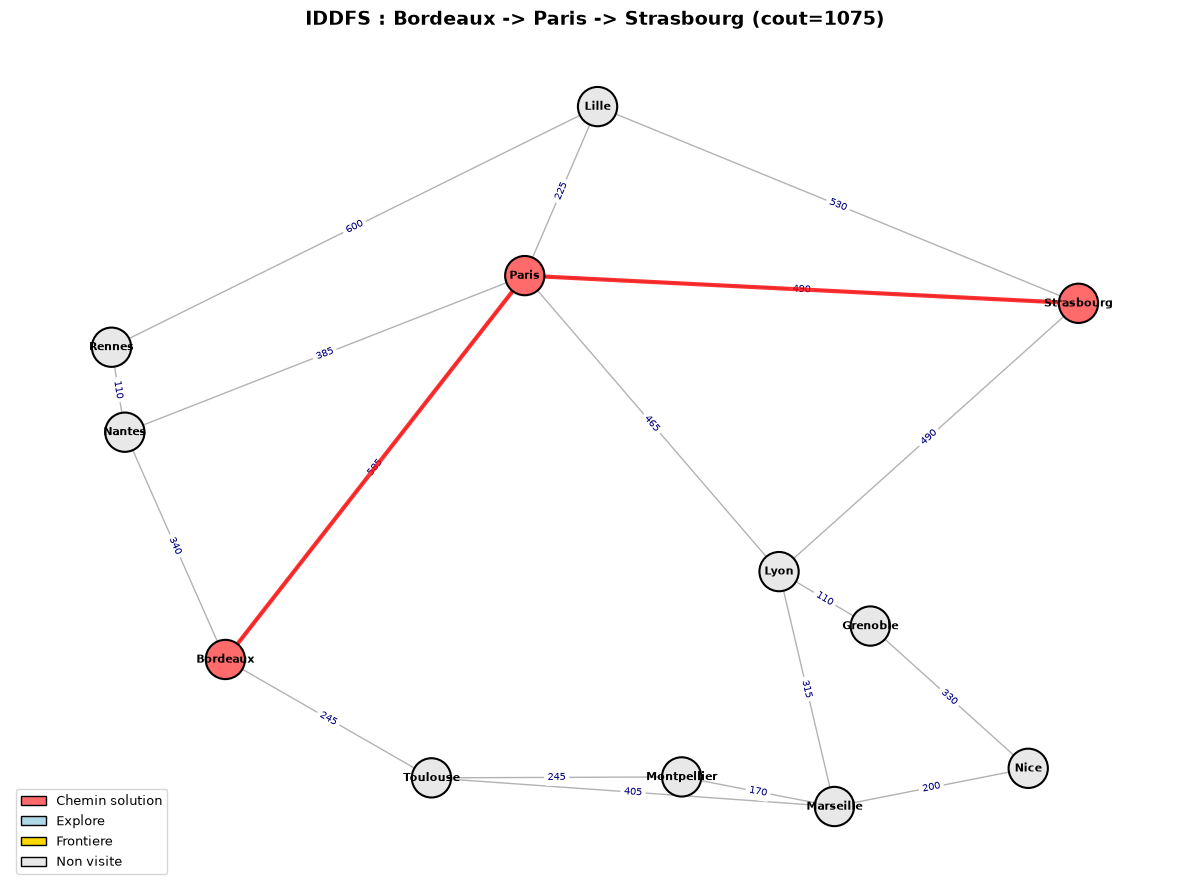

In [22]:
# Visualisation du résultat IDDFS
draw_france_graph(france_graph, france_coords,
                  path=result_iddfs.path,
                  explored=set(result_iddfs.explored_order),
                  title=f"IDDFS : {' -> '.join(result_iddfs.path)} (cout={result_iddfs.cost})")

### Analyse de l'overhead de IDDFS

Calculons l'overhead théorique de IDDFS par rapport a BFS sur un arbre regulier.

In [23]:
# --- Analyse de l'overhead de IDDFS ---

def compute_overhead(b, d):
    """Calcule le ratio noeuds generes IDDFS / BFS pour un arbre regulier."""
    # BFS genere b + b^2 + ... + b^d = b*(b^d - 1)/(b-1)
    bfs_nodes = sum(b**i for i in range(1, d+1))

    # IDDFS genere d*b + (d-1)*b^2 + ... + 1*b^d
    iddfs_nodes = sum((d - i + 1) * b**i for i in range(1, d+1))

    return bfs_nodes, iddfs_nodes, iddfs_nodes / bfs_nodes

print("Overhead de IDDFS par rapport a BFS")
print("=" * 60)
print(f"{'b':>3} {'d':>3} {'BFS noeuds':>15} {'IDDFS noeuds':>15} {'Ratio':>10}")
print("-" * 60)

for b in [2, 5, 10]:
    for d in [3, 5, 10]:
        bfs_n, iddfs_n, ratio = compute_overhead(b, d)
        print(f"{b:>3} {d:>3} {bfs_n:>15,} {iddfs_n:>15,} {ratio:>10.3f}")

Overhead de IDDFS par rapport a BFS
  b   d      BFS noeuds    IDDFS noeuds      Ratio
------------------------------------------------------------
  2   3              14              22      1.571
  2   5              62             114      1.839
  2  10           2,046           4,072      1.990
  5   3             155             190      1.226
  5   5           3,905           4,875      1.248
  5  10      12,207,030      15,258,775      1.250
 10   3           1,110           1,230      1.108
 10   5         111,110         123,450      1.111
 10  10  11,111,111,110  12,345,679,000      1.111


### Interpretation - Overhead de IDDFS

**Sortie obtenue** : le tableau montre que l'overhead de IDDFS **diminue** quand le facteur de branchement $b$ augmente.

| Branchement $b$ | Overhead approximatif |
|-----------------|----------------------|
| $b = 2$ | ~2x plus de noeuds |
| $b = 5$ | ~1.25x plus de noeuds |
| $b = 10$ | ~1.11x plus de noeuds |

**Explication** : quand $b$ est grand, le dernier niveau contient $b^d$ noeuds, ce qui domine largement les niveaux précédents. Les re-explorations des niveaux superieurs deviennent negligeables.

> **Conclusion** : pour $b \geq 5$ (très courant en pratique), l'overhead est inferieur a 25%. Le gain en memoire ($O(bd)$ vs $O(b^d)$) justifie largement ce surcout.

## 7. Comparaison des algorithmes

Comparons les quatre algorithmes sur le même problème pour observer leurs différences en pratique.

In [24]:
# --- Comparaison complète sur plusieurs problèmes ---

test_cases = [
    ('Bordeaux', 'Strasbourg'),
    ('Rennes', 'Nice'),
    ('Lille', 'Toulouse'),
    ('Nantes', 'Marseille'),
]

all_results = []

print("Comparaison des algorithmes sur plusieurs problemes")
print("=" * 80)

for start, goal in test_cases:
    problem = GraphProblem(start, goal, france_graph)

    results = {
        'BFS': breadth_first_search(problem),
        'DFS': depth_first_search(problem),
        'UCS': uniform_cost_search(problem),
        'IDDFS': iterative_deepening_search(problem),
    }

    print(f"\n{start} -> {goal}")
    print("-" * 80)
    print(f"{'Algo':<8} {'Chemin':<40} {'Cout':>8} {'Explores':>10} {'Generes':>10}")
    print("-" * 80)

    for name, result in results.items():
        path_str = ' -> '.join(result.path) if result.found else 'NON TROUVE'
        if len(path_str) > 38:
            path_str = path_str[:35] + '...'
        print(f"{name:<8} {path_str:<40} {result.cost:>8.0f} "
              f"{result.nodes_expanded:>10} {result.nodes_generated:>10}")

    all_results.append((start, goal, results))

Comparaison des algorithmes sur plusieurs problemes

Bordeaux -> Strasbourg
--------------------------------------------------------------------------------
Algo     Chemin                                       Cout   Explores    Generes
--------------------------------------------------------------------------------
BFS      Bordeaux -> Paris -> Strasbourg              1075          2          6
DFS      Bordeaux -> Nantes -> Rennes -> Lil...       1580          4         11
UCS      Bordeaux -> Paris -> Strasbourg              1075         10         31
IDDFS    Bordeaux -> Paris -> Strasbourg              1075          3          7

Rennes -> Nice
--------------------------------------------------------------------------------
Algo     Chemin                                       Cout   Explores    Generes
--------------------------------------------------------------------------------
BFS      Rennes -> Nantes -> Paris -> Lyon -...       1475          9         29
DFS      Rennes -

### Interpretation - Comparaison experimentale

**Observations** :

| Algorithme | Trouve le chemin... | Cout du chemin | Memoire |
|------------|--------------------|----|--------|
| **BFS** | Le moins profond (min d'étapes) | Pas forcement minimal en distance | Elevee |
| **DFS** | Le premier en profondeur | Souvent sous-optimal | Faible |
| **UCS** | De cout minimal (distance minimale) | **Optimal** | Elevee |
| **IDDFS** | Le moins profond (comme BFS) | Optimal si couts uniformes | **Faible** |

**Points cles** :
1. **UCS** donne toujours le **meilleur cout** quand les distances varient
2. **BFS** et **IDDFS** donnent le même chemin (même profondeur), mais des couts différents de UCS
3. **DFS** peut trouver des chemins très longs et couteux
4. **IDDFS** explore plus de noeuds au total (overhead), mais utilise peu de memoire

In [25]:
# --- Tableau récapitulatif et graphique ---

# Tableau récapitulatif théorique
print("\nTableau récapitulatif des propriétés")
print("=" * 85)
print(f"{'Algorithme':<12} {'Complet?':<12} {'Optimal?':<15} "
      f"{'Temps':<18} {'Espace':<15} {'Frontiere':<10}")
print("-" * 85)
rows = [
    ('BFS',   'Oui',  'Oui*',  'O(b^d)',        'O(b^d)',        'FIFO'),
    ('DFS',   'Non',  'Non',   'O(b^m)',        'O(bm)',         'LIFO'),
    ('UCS',   'Oui',  'Oui',   'O(b^(1+C*/e))', 'O(b^(1+C*/e))', 'Priorite'),
    ('IDDFS', 'Oui',  'Oui*',  'O(b^d)',        'O(bd)',         'LIFO'),
]
for row in rows:
    print(f"{row[0]:<12} {row[1]:<12} {row[2]:<15} {row[3]:<18} {row[4]:<15} {row[5]:<10}")

print("\n* Optimal uniquement si tous les couts d'action sont identiques.")


Tableau récapitulatif des propriétés
Algorithme   Complet?     Optimal?        Temps              Espace          Frontiere 
-------------------------------------------------------------------------------------
BFS          Oui          Oui*            O(b^d)             O(b^d)          FIFO      
DFS          Non          Non             O(b^m)             O(bm)           LIFO      
UCS          Oui          Oui             O(b^(1+C*/e))      O(b^(1+C*/e))   Priorite  
IDDFS        Oui          Oui*            O(b^d)             O(bd)           LIFO      

* Optimal uniquement si tous les couts d'action sont identiques.


Visualisons maintenant ces résultats sous forme de graphiques en barres pour mieux comparer les performances.

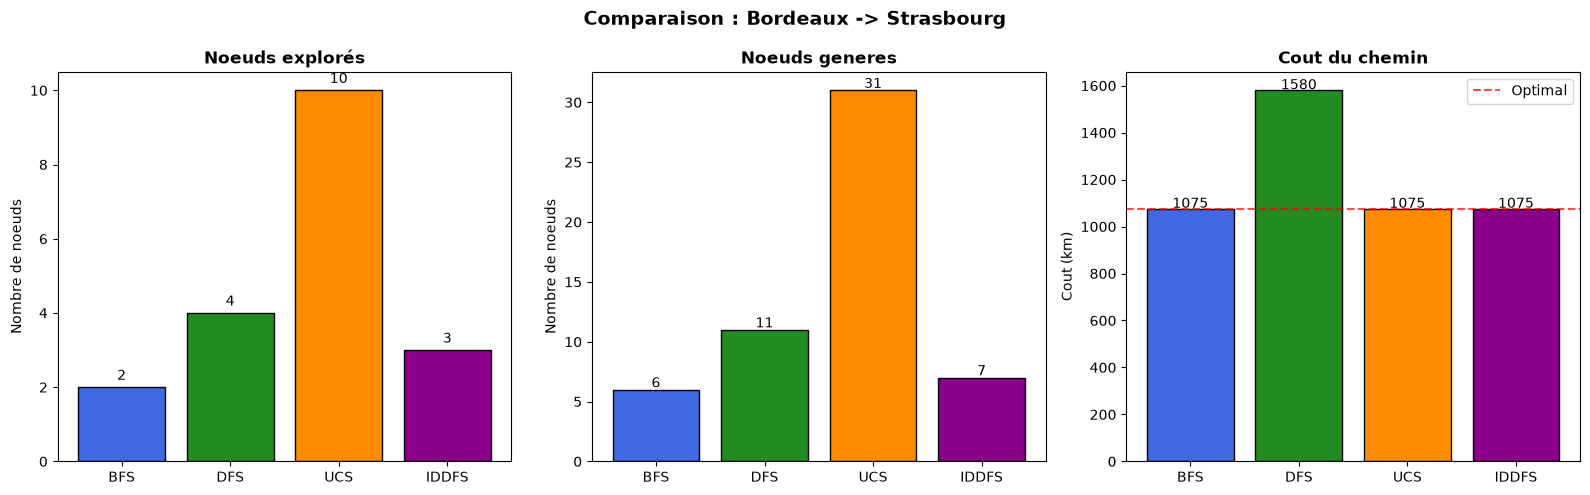

In [26]:
# --- Graphique comparatif ---

# Utiliser le premier problème (Bordeaux -> Strasbourg) pour le graphique
_, _, results_bs = all_results[0]

algos = ['BFS', 'DFS', 'UCS', 'IDDFS']
expanded = [results_bs[a].nodes_expanded for a in algos]
generated = [results_bs[a].nodes_generated for a in algos]
costs = [results_bs[a].cost for a in algos]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Noeuds explorés
colors = ['#4169E1', '#228B22', '#FF8C00', '#8B008B']
axes[0].bar(algos, expanded, color=colors, edgecolor='black')
axes[0].set_ylabel('Nombre de noeuds')
axes[0].set_title('Noeuds explorés', fontweight='bold')
for i, v in enumerate(expanded):
    axes[0].text(i, v + 0.2, str(v), ha='center', fontsize=10)

# Noeuds generes
axes[1].bar(algos, generated, color=colors, edgecolor='black')
axes[1].set_ylabel('Nombre de noeuds')
axes[1].set_title('Noeuds generes', fontweight='bold')
for i, v in enumerate(generated):
    axes[1].text(i, v + 0.2, str(v), ha='center', fontsize=10)

# Cout de la solution
axes[2].bar(algos, costs, color=colors, edgecolor='black')
axes[2].set_ylabel('Cout (km)')
axes[2].set_title('Cout du chemin', fontweight='bold')
for i, v in enumerate(costs):
    axes[2].text(i, v + 5, f"{v:.0f}", ha='center', fontsize=10)

# Marquer le cout optimal
optimal_cost = min(costs)
axes[2].axhline(y=optimal_cost, color='red', linestyle='--', alpha=0.7, label='Optimal')
axes[2].legend()

plt.suptitle('Comparaison : Bordeaux -> Strasbourg', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation - Graphiques comparatifs

Les trois graphiques montrent les compromis entre les algorithmes :

| Critere | Meilleur algorithme | Explication |
|---------|--------------------|--------------|
| Noeuds explores | DFS ou BFS (selon le graphe) | DFS peut trouver vite si le but est "en profondeur" |
| Cout du chemin | UCS | Seul algorithme garantissant l'optimalite avec couts variables |
| Memoire | DFS / IDDFS | Complexite spatiale lineaire vs exponentielle |

**Synthese** :
- Si les couts sont **uniformes** et la memoire est **limitee** : utiliser **IDDFS**
- Si les couts sont **variables** : utiliser **UCS**
- Si on a **assez de memoire** et les couts sont uniformes : **BFS** est le plus simple
- **DFS** est rarement le meilleur choix seul, mais il est utile comme sous-routine (dans IDDFS)

### Exercice 3 : Comparaison experimentale personnalisee

**Objectif** : Comparez les 4 algorithmes sur un trajet de votre choix et analysez les résultats.

Choisissez un trajet dans le graphe `france_graph` qui met en evidence une différence notable entre les algorithmes (par exemple un trajet ou UCS trouve un chemin nettement moins couteux que BFS).

**Consignes** :
1. Choisissez un depart et une arrivee dans `france_graph`
2. Executez les 4 algorithmes (BFS, DFS, UCS, IDDFS) sur ce trajet
3. Affichez un tableau comparatif : chemin, cout, noeuds explores
4. Identifiez quel algorithme trouve le chemin optimal et pourquoi

**Indices** :
- Un trajet long (4+ étapes) montrera mieux les différences
- Comparez le cout BFS vs UCS pour voir l'impact des couts non uniformes
- Utilisez `SearchResult.display()` pour afficher chaque résultat

In [27]:
# --- Exercice 3 : Comparaison experimentale personnalisee ---

# TODO étudiant : choisissez un depart et une arrivee
depart = None    # TODO etudiant : remplacer par une ville (ex: 'Grenoble')
arrivee = None   # TODO etudiant : remplacer par une ville (ex: 'Lille')

# TODO étudiant : instanciez le problème
# problem_custom = GraphProblem(depart, arrivee, france_graph)

# TODO étudiant : exécutez les 4 algorithmes
# Etape 1 : res_bfs = breadth_first_search(problem_custom)
# Etape 2 : res_dfs = depth_first_search(problem_custom)
# Etape 3 : res_ucs = uniform_cost_search(problem_custom)
# Etape 4 : res_iddfs = iterative_deepening_search(problem_custom)

# TODO étudiant : affichez un tableau comparatif
# Indice : utilisez result.display() pour chaque résultat

print("Exercice a completer")

Exercice a completer


## 8. Exemple guide

### Exemple guide 1 : Trace manuelle de BFS

Considerez le graphe suivant (couts uniformes) :

```
        A
       / \
      B   C
     / \   \
    D   E   F
   /       / \
  G       H   I (but)
```

**Question** : Tracez l'exécution de BFS depuis A vers I. A chaque étape, indiquez le contenu de la frontiere et l'ensemble des etats explores.

**Indice** : Utilisez le code ci-dessous pour verifier votre reponse.

#### Initialisation
- Frontière : [A]
- Explorés : Aucun

**étape 1 : Expansion de A**
A génère B et C
- Frontière : [B,C]
- Explorés : {A}
**étape 2 : Expansion de B**
B génère D et E (A est ignoré car déjà exploré)
- Frontière : [C, D, E]
- Explorés : {A,B}
**étape 3 : Expansion de C**
C génère F (A ignoré)
- Frontière [D, E, F]
- Explorés : {A,B,C}
**étape 4 : Expansion de D**
D génère G
- Frontière : [E, F, G]
- Explorés : {A,B,C,D}
**étape 5 : Expansion de E**
E ne génère aucun nouvel état
- Frontière : [F, G]
- Explorés : {A,B,C,D,E}
**étape 6 : Expansion de F**
F génère H et I, I est l'objectif donc arrêt de la recherche.
- Frontière : [G, H, I]
- Explorés : {A,B,C,D,E,F}

Le BFS trouve le but I via le chemin A -> C -> F -> I
La solution est optimale car BFS explore par niveaux (coûts uniformes)

In [28]:
# --- Exemple guide 1 : Trace BFS sur un petit graphe ---

exercise_graph = {
    'A': {'B': 1, 'C': 1},
    'B': {'A': 1, 'D': 1, 'E': 1},
    'C': {'A': 1, 'F': 1},
    'D': {'B': 1, 'G': 1},
    'E': {'B': 1},
    'F': {'C': 1, 'H': 1, 'I': 1},
    'G': {'D': 1},
    'H': {'F': 1},
    'I': {'F': 1},
}

ex1_problem = GraphProblem('A', 'I', exercise_graph)

print("Exemple guide 1 - Trace BFS de A a I")
print("=" * 50)
ex1_result = breadth_first_search(ex1_problem, verbose=True)
ex1_result.display()

Exemple guide 1 - Trace BFS de A a I
  Explore: A               | Frontiere: []
  Explore: B               | Frontiere: ['C']
  Explore: C               | Frontiere: ['D', 'E']
  Explore: D               | Frontiere: ['E', 'F']
  Explore: E               | Frontiere: ['F', 'G']
  Explore: F               | Frontiere: ['G']

--- BFS ---
  Chemin     : A -> C -> F -> I
  Cout total : 3
  Longueur   : 3 étapes
  Noeuds explorés  : 6
  Noeuds generes   : 13
  Frontiere max    : 3
  Temps            : 0.24 ms


### Exemple guide 2 : Quand DFS est meilleur que BFS

**Question** : Donnez un exemple de problème ou DFS explore **strictement moins** de noeuds que BFS pour trouver la solution. Expliquez pourquoi.

**Indice** : Pensez a un arbre ou la solution est a grande profondeur mais accessible par la première branche.

DFS peut être meilleur que BFS dans un arbre très profond et peu large, où la solution se trouve très profondément dans la première branche explorée. Par exemple : profondeur de 8, facteur de branchement de 3, avec un objectif placé sur la première branche gauche.

Le BFS explore tous les noeuds par niveau, donc on explore toutes les branches proches du niveau 0, 1, 2 etc. L'exploration devient exponentielle en largeur et beaucoup de noeuds sont visités avant d'atteindre la profondeur 8.

Le DFS, quant à lui, va explorer une branche complète avant de revenir en arrière et ici il choisi directement la branche gauche. Il descend directement jusqu'à la solution, ce qui implique que très peu de noeuds sont explorés.

DFS est meilleur quand la solution est profonde et bien orentiée dans l'ordre d'exploration, tandis que BFS souffre de l'explosion combinatoire en largeur.

In [29]:
# --- Exemple guide 2 : Construction d'un cas favorable a DFS ---
#
# Objectif : construire un problème de graphe ou DFS explore
# strictement moins de noeuds que BFS.
#
# Indices :
#   1. Creez un arbre regulier avec `depth` et `branching` eleves
#      (ex : depth=8, branching=3).
#   2. Placez le but sur la PREMIERE branche exploree par DFS
#      (la branche "la plus a gauche").
#   3. Comparez le nombre de noeuds explorés par breadth_first_search
#      et depth_first_search sur ce problème.
#
# A completer :

# deep_graph = {}
# depth = ?
# branching = ?

deep_graph = {}
depth = 8
branching = 3

# Exemple guide: construire l'arbre dans deep_graph
for i in range(depth):
    for j in range(branching**i):
        node = f"L{i}_{j}"
        deep_graph[node] = {}
        if i < depth - 1:
            for k in reversed(range(branching)):
                fils = f"L{i+1}_{j*branching + k}"
                deep_graph[node][fils] = 1


# Exemple guide: définir goal_dfs (la feuille atteinte par la première branche)
# goal_dfs = ...
goal_dfs = f"L{depth - 1}_0"

# Exemple guide: instancier GraphProblem('L0_0', goal_dfs, deep_graph)
# problem_deep = ...
problem_deep = GraphProblem('L0_0', goal_dfs, deep_graph)

# Exemple guide: executer breadth_first_search et depth_first_search
# result_bfs_deep = ...
# result_dfs_deep = ...
result_bfs_deep = breadth_first_search(problem_deep)
result_dfs_deep = depth_first_search(problem_deep)


# Exemple guide: comparer les compteurs de noeuds explorés (attribut .counts
# ou count de result.display() selon l'implémentation utilisée).
print("\nComparaison BFS vs DFS sur le cas profond")
print("-" * 50)
print(f"BFS : {result_bfs_deep.nodes_expanded} noeuds explorés, "
      f"chemin de longueur {len(result_bfs_deep.path)-1}")
print(f"DFS : {result_dfs_deep.nodes_expanded} noeuds explorés, "
        f"chemin de longueur {len(result_dfs_deep.path)-1}")

print("Exemple guide 2 : construction et comparaison terminees.")



Comparaison BFS vs DFS sur le cas profond
--------------------------------------------------
BFS : 1093 noeuds explorés, chemin de longueur 7
DFS : 7 noeuds explorés, chemin de longueur 7
Exemple guide 2 : construction et comparaison terminees.


### Exemple 3 : Recherche bidirectionnelle (BFS)

**Principe** : lancez simultanement un BFS depuis l'etat initial et un BFS depuis l'etat but. Les deux recherches s'arretent quand leurs frontieres se rencontrent.

**Avantage théorique** : complexite en $O(b^{d/2})$ au lieu de $O(b^d)$.


In [30]:
# --- Exemple 3 : BFS bidirectionnel ---

def bidirectional_bfs(problem, graph, verbose=False):
    """
    Recherche bidirectionnelle BFS.
    Lance un BFS depuis initial et un BFS depuis goal,
    et s'arrete quand les frontieres se rencontrent.
    """
    start_time = time.perf_counter()

    # Initialiser les structures pour BFS avant et arrière
    frontier_fwd = deque([problem.initial])
    parent_fwd = {problem.initial: None}
    frontier_bwd = deque([problem.goal])
    parent_bwd = {problem.goal: None}
    expanded_nodes = 0
    central_point = None

    # Boucle principale : alterner expansion avant/arrière
    # Detecter le point de rencontre (noeud present dans les deux parent dicts)
    while frontier_fwd and frontier_bwd:
        if frontier_fwd:
            current_fwd = frontier_fwd.popleft()
            expanded_nodes += 1

            for i in graph.get(current_fwd, {}):
                if i not in parent_fwd:
                    parent_fwd[i] = current_fwd
                    frontier_fwd.append(i)
                    if i in parent_bwd:
                        central_point = i
                        break
            if central_point:
                break

        if frontier_bwd:
            current_bwd = frontier_bwd.popleft()
            expanded_nodes += 1

            for j in graph.get(current_bwd, {}):
                if j not in parent_bwd:
                    parent_bwd[j] = current_bwd
                    frontier_bwd.append(j)
                    if j in parent_fwd:
                        central_point = j
                        break
            if central_point:
                break
    elapsed = (time.perf_counter() - start_time) * 1000
    if central_point is None:
        return None

    # Reconstruire le chemin complet via les deux parent dicts
    path = []
    node = central_point
    while node is not None:
        path.append(node)
        node = parent_fwd[node]
    path.reverse()

    path2 = []
    node = parent_bwd[central_point]
    while node is not None:
        path2.append(node)
        node = parent_bwd[node]
    global_path = path + path2

    total_cost = sum(graph[global_path[i]][global_path[i+1]] for i in range(len(global_path)-1))
    if verbose:
        print(f"point de rencontre: {central_point}")
        print(f"chemin trouve: {' -> '.join(global_path)} (cout={total_cost})")
        print(f"noeuds explorés: {expanded_nodes} en {elapsed:.2f} ms")
    return global_path, total_cost, expanded_nodes

print("BFS bidirectionnel : Bordeaux -> Strasbourg")
print("=" * 50)
bi_result = bidirectional_bfs(problem_bs, france_graph, verbose=True)

# Comparer avec BFS classique
print("\nComparaison :")
print(f"  BFS classique     : {result_bfs.nodes_expanded} noeuds explorés")
if bi_result:
    print(f"  BFS bidirectionnel: {bi_result[2]} noeuds explorés")


BFS bidirectionnel : Bordeaux -> Strasbourg
point de rencontre: Paris
chemin trouve: Bordeaux -> Paris -> Strasbourg (cout=1075)
noeuds explorés: 2 en 0.01 ms

Comparaison :
  BFS classique     : 2 noeuds explorés
  BFS bidirectionnel: 2 noeuds explorés


### Exemple guide 3 : IDS avec suivi de memoire

**Question** : Implementez une variante de la recherche en profondeur iteree (IDS) qui suit en detail la consommation memoire a chaque itération.

**Objectifs** :
1. Ecrire une fonction `ids_with_memory()` qui enregistre a chaque profondeur : le nombre de noeuds explores, generes, et la taille maximale de la pile d'appels
2. Comparer l'evolution de la memoire de IDS avec celle de BFS sur le problème **Rennes -> Nice** (le plus profond du notebook)

**Contexte** : IDS est reconnu pour sa faible empreinte memoire ($O(bd)$) contre $O(b^d)$ pour BFS. Cet exercice vous demande de le verifier experimentalement.


In [31]:
# --- Exemple guide 3 : IDS avec suivi de mémoire ---
#
# Objectif : implémentez iterative_deepening_search avec un suivi détaillé
# de la mémoire utilisée a chaque itération.
#
# 1. Completez la fonction ids_with_memory() qui : 
#    - Execute des DLS avec des profondeurs croissantes (0, 1, 2, ...)
#    - A chaque itération, enregistre :
#      * La profondeur limite
#      * Le nombre de noeuds explorés
#      * Le nombre de noeuds generes
#      * La taille maximale de la pile (mémoire)
#    - Retourne un objet SearchResult et un dictionnaire memory_log
#
# 2. Comparez la consommation mémoire de IDS avec celle de BFS
#    sur le problème Rennes -> Nice (le plus profond du notebook).
#
# Indices :
#   - Utilisez depth_limited_search comme sous-routine
#   - Pour mesurer la mémoire, comptez le nombre d'éléments dans la pile
#     récursive (profondeur d'appel = mémoire utilisée)
#   - Un dictionnaire memory_log peut contenir : {"depth": [...], "memory": [...]}
#

def ids_with_memory(problem, max_depth=50, verbose=False):
    """
    IDS avec suivi detaille de la memoire.
    
    Retourne: (SearchResult, memory_log)
        memory_log = {"depth": [...], "expanded": [...], "memory": [...]}
    """
    # Exemple guide: implémentation de cette fonction
    memory_log = {
        "depth": [],
        "expanded": [],
        "generated": [],
        "memory": []
    }

    total_expanded = 0
    total_generated = 0

    def dls(node, depth, limit, visited):
        nonlocal expanded, generated, max_memory

        max_memory = max(max_memory, depth)

        if problem.goal_test(node):
            return [node]

        if depth == limit:
            return None

        expanded += 1

        for child in problem.actions(node):
            generated += 1
            if child not in visited:
                visited.add(child)
                path = dls(child, depth + 1, limit, visited)
                if path:
                    return [node] + path

        return None

    for limit in range(max_depth + 1):
        expanded = 0
        generated = 0
        max_memory = 0

        visited = set([problem.initial])

        path = dls(problem.initial, 0, limit, visited)

        memory_log["depth"].append(limit)
        memory_log["expanded"].append(expanded)
        memory_log["generated"].append(generated)
        memory_log["memory"].append(max_memory)

        total_expanded += expanded
        total_generated += generated

        if verbose:
            print(f"Profondeur {limit} | expanded={expanded} | memory={max_memory}")

        if path:
            # Création d'un résultat simple compatible
            class Result:
                def __init__(self, path, expanded):
                    self.path = path
                    self.nodes_expanded = expanded

            return Result(path, total_expanded), memory_log

    return None, memory_log
# Exemple guide: exécutez ids_with_memory sur le problème Rennes -> Nice
# problem_rn = GraphProblem('Rennes', 'Nice', france_graph)
# result_ids, mem_log = ids_with_memory(problem_rn, verbose=True)

# Exemple guide: affichez un graphique comparant la mémoire de IDS vs BFS
# avec plt.plot(mem_log["depth"], mem_log["memory"], label="IDS")

print("Exemple guide 3 a completer")

Exemple guide 3 a completer


### Algorithme supplementaire

Implementation complementaire des méthodes de recherche non informee.

In [32]:
problem_rn = GraphProblem('Rennes', 'Nice', france_graph)

result_ids, mem_log = ids_with_memory(problem_rn, verbose=True)

print("\nIDS terminé")
print(f"Chemin : {result_ids.path}")
print(f"Noeuds explorés : {result_ids.nodes_expanded}")

Profondeur 0 | expanded=0 | memory=0
Profondeur 1 | expanded=1 | memory=1
Profondeur 2 | expanded=3 | memory=2
Profondeur 3 | expanded=3 | memory=3
Profondeur 4 | expanded=6 | memory=4
Profondeur 5 | expanded=5 | memory=5

IDS terminé
Chemin : ['Rennes', 'Nantes', 'Paris', 'Lyon', 'Marseille', 'Nice']
Noeuds explorés : 18


IDS explore en profondeur limitée croissante, la mémoire utilisée est équivalente à la profondeur courante, avec une faible empreinte mémoire. Ici, on a une mémoire max = 5 et une croissance linéaire.

Pour le BFS, on stocke tous les noeuds d'un niveau et la mémoire grandit exponentiellement en fonction de la profondeur.

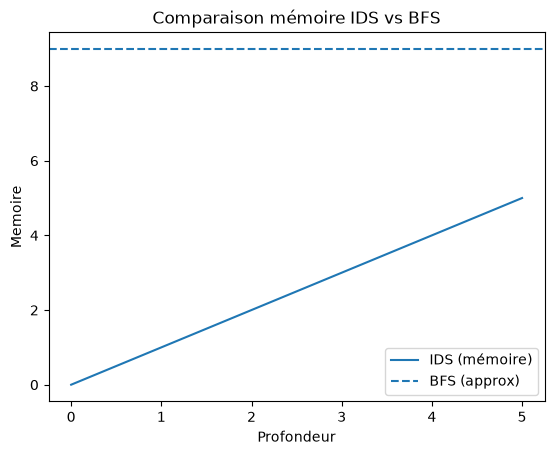

In [33]:
import matplotlib.pyplot as plt

# BFS pour comparaison
result_bfs = breadth_first_search(problem_rn)

# Courbe IDS
plt.plot(mem_log["depth"], mem_log["memory"], label="IDS (mémoire)")

# Ligne BFS (constante)
plt.axhline(y=result_bfs.nodes_expanded, linestyle='--', label="BFS (approx)")

plt.xlabel("Profondeur")
plt.ylabel("Memoire")
plt.title("Comparaison mémoire IDS vs BFS")
plt.legend()
plt.show()

### Exercice 4 (capstone) : implementer la recherche bidirectionnelle

La **recherche bidirectionnelle** est le seul grand algorithme de recherche non informee demontre plus haut (Exemple 3) sans que vous l'ayez implemente vous-meme. L'idee : lancer **deux** BFS en parallele, l'une depuis la **source**, l'autre depuis le **but** (en parcourant les aretes a l'envers), et s'arreter des que leurs frontieres se rencontrent.

L'interet est asymptotique : si `b` est le facteur de branchement et `d` la profondeur de la solution, une BFS classique developpe de l'ordre de `O(b^d)` noeuds, alors que la version bidirectionnelle n'en developpe que `O(2 * b^(d/2))` — un gain **quadratique** qui devient decisif sur les graphes profonds.

**Objectif.** Re-implementer la BFS bidirectionnelle *from scratch* sur le graphe des villes, choisir un couple (source, but) eloigne, et mesurer le nombre de noeuds expandus par rapport a la BFS classique pour quantifier le gain.

- *Indice 1* : ecrire une fonction `bfs_depuis(problem, depart, max_expansions)` qui renvoie un dict `explores : noeud -> parent` apres `max_expansions` developpements.
- *Indice 2* : inverser le graphe pour la BFS partant du but (construire un dict `predecesseurs : noeud -> liste de predecesseurs` a partir de `problem.graph`).
- *Indice 3* : a chaque etape, verifier l'intersection entre les deux ensembles explores ; quand un noeud appartient aux deux, reconstruire le chemin en remontant les parents des deux cotes. Comparer le compte total d'expansions (somme des deux moities) au compte d'une BFS classique sur le meme couple.

In [34]:
# Exercice 4 (capstone) : implementer la recherche bidirectionnelle (BFS)
# L'Exemple 3 ci-dessus MONTRE une recherche bidirectionnelle ; a votre tour
# de l'implementer from scratch sur un nouveau couple (source, but).
# Etape 1 : ecrire bfs_depuis(problem, depart) qui renvoie la frontiere
#           exploree (un dict noeud -> parent) apres K expansions.
# Etape 2 : lancer deux BFS simultanees, l'une depuis la source, l'autre
#           depuis le but (en inversant les aretes), jusqu'a intersection.
# Etape 3 : comparer le nombre de noeuds expands par la BFS bidirectionnelle
#           vs la BFS classique sur le meme couple ; commenter le gain.
# Indice : si b est le facteur de branchement et d la profondeur de la
#          solution, la BFS classique developpe ~O(b^d) noeuds ; la
#          bidirectionnelle ~O(2*b^(d/2)), soit un gain quadratique.
resultat = None  # TODO etudiant
print("Exercice a completer : implementer la BFS bidirectionnelle.")

Exercice a completer : implementer la BFS bidirectionnelle.


### Exercice 5 : Le chemin optimal dépend de la fonction de coût

UCS est optimal **pour la fonction de coût qu'on lui donne**, et pour aucune autre. Pour le voir, changeons la fonction de coût sans toucher à la carte : chaque route qui entre dans Paris ou en sort reçoit une pénalité d'embouteillage de 200 km équivalents.

**Tâche** :
1. Écrire `graphe_penalise(graph, ville, penalite)` : une **copie** de `france_graph` où chaque arête touchant `ville` coûte `penalite` de plus, dans les deux sens. Le graphe d'origine ne doit pas être modifié.
2. Lancer BFS et UCS sur Bordeaux → Strasbourg, avec le graphe d'origine, puis avec le graphe pénalisé.
3. Comparer les quatre résultats.

**Vérification** : sur le graphe pénalisé, UCS doit trouver un chemin de 1 455 km en 4 étapes.

**Questions** :
- Le chemin rendu par BFS change-t-il ? Pourquoi ?
- Sur le graphe pénalisé, le chemin via Paris coûterait 1 475 km. À partir de quelle pénalité UCS cesse-t-il de passer par Paris ?

**Indice** : `{a: dict(voisins) for a, voisins in graph.items()}` copie les deux niveaux du dictionnaire.

In [35]:
# --- Exercice 5 : le chemin optimal depend de la fonction de cout ---

PENALITE_PARIS = 200   # km "equivalents" ajoutes a chaque route qui touche Paris

def graphe_penalise(graph, ville, penalite):
    # TODO etudiant : renvoyer une COPIE de graph ou chaque arete touchant 'ville'
    # coute 'penalite' de plus (dans les deux sens), sans modifier graph
    return None  # TODO etudiant


# --- Test (decommentez apres avoir complete l'exercice ci-dessus) ---
# g_pen = graphe_penalise(france_graph, 'Paris', PENALITE_PARIS)
# assert france_graph['Bordeaux']['Paris'] == 585      # l'original n'a pas bouge
# for nom, g in (("original", france_graph), ("penalise", g_pen)):
#     pb = GraphProblem('Bordeaux', 'Strasbourg', g)
#     rb, ru = breadth_first_search(pb), uniform_cost_search(pb)
#     print(f"{nom:9s} | BFS : {' -> '.join(rb.path)} ({rb.cost} km)")
#     print(f"{'':9s} | UCS : {' -> '.join(ru.path)} ({ru.cost} km)")

print("Exercice a completer")

Exercice a completer


## 9. Resume

### Concepts cles

| Concept | Definition |
|---------|------------|
| **Recherche non informee** | Exploration sans connaissance du domaine (pas d'heuristique) |
| **Frontiere** | Ensemble des noeuds generes mais pas encore explores |
| **Ensemble explore** | Noeuds déjà etendus (graph-search) |
| **Completude** | Garantie de trouver une solution si elle existe |
| **Optimalite** | Garantie de trouver la solution de cout minimal |

### Tableau recapitulatif

| Algorithme | Complet? | Optimal? | Temps | Espace | Frontiere |
|------------|----------|----------|-------|--------|----------|
| **BFS** | Oui | Oui* | $O(b^d)$ | $O(b^d)$ | FIFO |
| **DFS** | Non | Non | $O(b^m)$ | $O(bm)$ | LIFO |
| **UCS** | Oui | Oui | $O(b^{1+\lfloor C^*/\epsilon \rfloor})$ | $O(b^{1+\lfloor C^*/\epsilon \rfloor})$ | Priorite |
| **IDDFS** | Oui | Oui* | $O(b^d)$ | $O(bd)$ | LIFO |

\* Optimal uniquement si tous les couts d'action sont identiques.

### Guide de choix

| Situation | Algorithme recommande |
|-----------|----------------------|
| Couts uniformes, memoire limitee | IDDFS |
| Couts uniformes, memoire abondante | BFS |
| Couts variables | UCS |
| Memoire très limitee, pas besoin d'optimalite | DFS |
| Heuristique disponible | Voir Search-3 (A*, Greedy) |


***

**Navigation** : [<< Espaces d'etats](Search-01-StateSpace.ipynb) | [Index](../README.md) | [Recherche informee >>](Search-03-Informed.ipynb)

## Resume et perspectives

Ce notebook a couvert les quatre algorithmes fondamentaux de recherche non informee -- BFS, DFS, UCS et IDDFS -- en mettant en evidence le rôle central de la **structure de la frontiere** (FIFO, LIFO ou file de priorite) dans la definition de chaque stratégie. Vous avez pu observer experimentalement que seul UCS garantit l'optimalite en presence de couts variables, tandis que IDDFS offre le meilleur compromis completite-optimalite-memoire quand les couts sont uniformes.

Ces méthodes aveugles posent les bases necessaires pour aborder la recherche **informee** (notebook Search-03-Informed), ou une heuristique $h(n)$ permettra de guider l'exploration et de reduire drastiquement le nombre de noeuds explores. Le passage de UCS a A* sera alors naturel : il s'agit simplement d'ajouter l'heuristique au cout déjà accumule.


### References academiques

- Moore, E.F. (1959). The shortest path through a maze. Proc. Int. Symp. Theory of Switching.
- Tarjan, R. (1972). Depth-first search and linear graph algorithms. SIAM Journal on Computing 1(2):146-160.
- Dijkstra, E.W. (1959). A note on two problems in connexion with graphs. Numerische Mathematik 1:269-271.
- Korf, R.E. (1985). Depth-first iterative-deepening: an optimal admissible tree search. Artificial Intelligence 27(1):97-109.
- Russell, S. & Norvig, P. (2020). Artificial Intelligence: A Modern Approach (4th ed.). Pearson.



## À retenir

1. **La stratégie de recherche vit dans la structure de la frontière** : FIFO (BFS), LIFO (DFS), file de priorité sur $g(n)$ (UCS) — un même cadre, trois politiques d'expansion.
2. **Le cas discriminant Paris → Rennes** : deux chemins de 2 étapes, BFS rend 825 km via Lille, UCS rend **495 km via Nantes** (40 % d'écart) — BFS n'est optimal qu'à coûts uniformes ; sur Bordeaux → Strasbourg au contraire, les deux convergent (1 075 km) et l'avantage de UCS est invisible.
3. DFS Bordeaux → Strasbourg rend **4 étapes / 1 580 km** (contre 2 / 1 075 pour BFS) : la première branche explorée n'a aucune raison d'être la bonne.
4. IDDFS retrouve le chemin de BFS avec une mémoire $O(bd)$ ; l'overhead de ré-exploration est **mesuré** dans le carnet : ~1,11× à $b = 10$, ~1,25× à $b = 5$, ~2× seulement à $b = 2$.
5. Sur Rennes → Nice, la mémoire d'IDS culmine à **5** (la profondeur courante) quand la frontière de BFS stocke un niveau entier — l'écart $O(bd)$ / $O(b^d)$ devient décisif sur les espaces profonds.

## Vérifiez votre compréhension

1. Pourquoi BFS et UCS trouvent-ils le même chemin sur Bordeaux → Strasbourg mais pas sur Paris → Rennes ?
2. Dans le trace UCS, Toulouse (coût cumulé 245) est explorée avant Paris (585). Qu'est-ce que cela illustre ?
3. Quel avantage IDS concède-t-il par rapport à BFS, et à quel prix mesuré ?
4. D'où vient le gain de la recherche bidirectionnelle (ex. guidé 3) ?

<details><summary>Réponses</summary>

1. Sur le premier trajet, le chemin minimal en étapes est aussi minimal en km ; sur le second, deux chemins de **même longueur** (2 étapes) ont des coûts très différents (825 vs 495 km) et BFS, aveugle aux poids, s'arrête au premier trouvé.
2. UCS étend toujours le nœud de **coût cumulé $g(n)$ minimal** : l'ordre d'expansion suit le coût croissant, pas la proximité en nombre de sauts.
3. Une mémoire linéaire $O(bd)$ contre $O(b^d)$, au prix d'un overhead de ré-exploration **décroissant avec $b$** : ~1,11× à $b = 10$, ~1,25× à $b = 5$, ~2× à $b = 2$ (tableau mesuré du carnet).
4. Chaque BFS ne descend qu'à **demi-profondeur** $d/2$ : chacune développe $\sim b^{d/2}$ nœuds, soit $2\,b^{d/2}$ au total contre $b^d$ — un gain quadratique.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Search-03-Informed](Search-03-Informed.ipynb) — Greedy Best-First et A* : ajouter une heuristique $h(n)$ au $g(n)$ de UCS.
- **Dans la même série** : [Search-02b-NetworkX](Search-02b-NetworkX.ipynb) (les mêmes parcours via le moteur networkx) et [Search-02c-QuikGraph](Search-02c-QuikGraph.ipynb) (le contrepoint .NET).
- **Carnet voisin d'une autre série** : [Sudoku-01-Backtracking-Python](../../Sudoku/Sudoku-01-Backtracking-Python.ipynb) — le retour arrière comme exploration en profondeur d'un espace d'états de grille.
- **Lectures** : les quatre papiers fondateurs cités en fin de carnet — Moore (1959) pour BFS, Dijkstra (1959) pour le plus court chemin, Tarjan (1972) pour DFS, Korf (1985) pour IDDFS.